# Taller formativo – Trabajo de la unidad ML
## Inspección del dataset: imágenes de caracteres (vocales)
**Inteligencia Artificial 2026-II**

**Integrantes:** _(escriba aquí los nombres del equipo)_

**Objetivo del taller:** inspeccionar y verificar la calidad del dataset asignado (imágenes de las vocales A, E, I, O, U) y hacer una primera exploración de sus variables, en especial de la variable a predecir (la vocal).

> Las celdas marcadas como **✍️ Análisis del equipo** están pensadas para que ustedes las redacten con sus propias palabras. Cada una incluye preguntas guía.

## 1. Descripción del problema

✍️ **Análisis del equipo.** Consulten documentación sobre reconocimiento de caracteres manuscritos/impresos (OCR) y sobre el origen del dataset `CNN letter dataset`. Describan con sus palabras:

- ¿En qué consiste el problema de clasificar imágenes de vocales y para qué sirve en la práctica?
- ¿Cuál es la variable de entrada (imagen) y cuál la variable a predecir (clase)?
- ¿Cómo fue construido el dataset según su documentación (fuente, si es aumentado, etc.)?
- Propongan un objetivo para el trabajo de aprendizaje supervisado.

**Fuentes consultadas:** _(listar enlaces)_

_(Escriba aquí su descripción)_

## 2. Configuración y carga del dataset

In [75]:
import os
import re
import zipfile
import hashlib
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)
np.random.seed(42)
plt.rcParams["figure.dpi"] = 100


# ---------------------------------------------------------------
RUTA_DATASET = r"C:\Users\FAMILIA P\Desktop\IA\CNN letter dataset"
RUTA_ZIP = "CNN_letter_dataset.zip"
EXT = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff"}


def _tiene_clases(carpeta: Path) -> bool:
    subs = [d for d in carpeta.iterdir() if d.is_dir() and not d.name.startswith(("__", "."))]
    con_imgs = [d for d in subs if any(f.suffix.lower() in EXT for f in d.iterdir() if f.is_file())]
    return len(con_imgs) >= 2


def encontrar_raiz() -> Path:
    # 1) ruta indicada
    p = Path(RUTA_DATASET)
    if p.is_dir() and _tiene_clases(p):
        return p
    # 2) descomprimir el zip si existe
    candidatos_zip = [Path(RUTA_ZIP), Path("/mnt/user-data/uploads") / RUTA_ZIP]
    for z in candidatos_zip:
        if z.is_file():
            destino = Path("dataset_extraido")
            if not destino.exists():
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(destino)
            break
    # 3) buscar en cualquier subcarpeta
    for base in [Path("dataset_extraido"), Path(".")]:
        if base.is_dir():
            for d in [base] + [x for x in base.rglob("*") if x.is_dir()]:
                if "__MACOSX" in d.parts:
                    continue
                if _tiene_clases(d):
                    return d
    raise FileNotFoundError(
        "No se encontró el dataset. Ajuste RUTA_DATASET o RUTA_ZIP en esta celda."
    )


RAIZ = encontrar_raiz()
print("Dataset encontrado en:", RAIZ.resolve())

Dataset encontrado en: C:\Users\FAMILIA P\Desktop\IA\CNN letter dataset


## 3. Organización de archivos y carpetas

El siguiente árbol muestra cómo está organizado el dataset y cuántos archivos tiene cada carpeta.

In [76]:
for carpeta, subs, archivos in os.walk(RAIZ):
    if "__MACOSX" in carpeta:
        continue
    nivel = len(Path(carpeta).relative_to(RAIZ).parts)
    print("  " * nivel + f"{Path(carpeta).name}/  ({len(archivos)} archivos)")

print("\nEjemplos de nombres de archivo:")
for d in sorted(x for x in RAIZ.iterdir() if x.is_dir()):
    print(f"  {d.name}: {[f.name for f in sorted(d.iterdir())[:3]]}")

CNN letter dataset/  (0 archivos)
  0/  (1030 archivos)
  A/  (1010 archivos)
  E/  (1010 archivos)
  I/  (1010 archivos)
  U/  (1010 archivos)

Ejemplos de nombres de archivo:
  0: ['aug17401_0.jpg', 'aug17402_1.jpg', 'aug17403_2.jpg']
  A: ['aug100_19.jpg', 'aug100_9.jpg', 'aug101_0.jpg']
  E: ['aug1061_0.jpg', 'aug1062_1.jpg', 'aug1063_2.jpg']
  I: ['aug2581_0.jpg', 'aug2582_1.jpg', 'aug2583_2.jpg']
  U: ['aug13601_0.jpg', 'aug13602_1.jpg', 'aug13603_2.jpg']


### Lectura de las imágenes
Se construye una tabla (`DataFrame`) con la ruta, la clase (nombre de la carpeta) y el formato de cada imagen. Se lee una imagen de ejemplo con `Pillow` y con `OpenCV` (si está instalado) para verificar que el acceso funciona.

**Nota:** en este dataset la carpeta de la letra O se llama `0` (cero). En el código se renombra la clase a `O` para evitar confusión con el dígito.

In [77]:
registros = []
for p in RAIZ.rglob("*"):
    if p.is_file() and p.suffix.lower() in EXT and "__MACOSX" not in p.parts:
        registros.append({"ruta": p, "clase": p.parent.name, "formato": p.suffix.lower()})

df = pd.DataFrame(registros)
df["clase"] = df["clase"].replace({"0": "O"}) 
CLASES = sorted(df["clase"].unique())

print("Total de imágenes:", len(df))
print("Clases:", CLASES)

df.groupby("clase").sample(1).sort_values("clase")

Total de imágenes: 5070
Clases: ['A', 'E', 'I', 'O', 'U']


,ruta,clase,formato
1659,C:\Users\FAMILIA P\Desktop\IA\CNN letter datas...,A,.jpg
2224,C:\Users\FAMILIA P\Desktop\IA\CNN letter datas...,E,.jpg
3763,C:\Users\FAMILIA P\Desktop\IA\CNN letter datas...,I,.jpg
252,C:\Users\FAMILIA P\Desktop\IA\CNN letter datas...,O,.jpg
4758,C:\Users\FAMILIA P\Desktop\IA\CNN letter datas...,U,.jpg


Pillow  -> tamaño (ancho, alto): (75, 100) | modo: L | formato: JPEG
NumPy   -> forma del arreglo (alto, ancho): (100, 75) | dtype: uint8
OpenCV  -> forma: (100, 75) | dtype: uint8


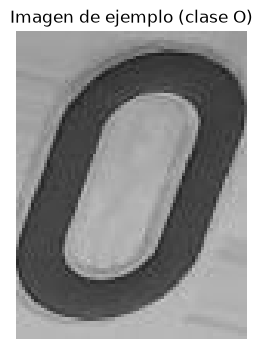

In [78]:
# Lectura de una imagen de ejemplo con Pillow
ejemplo = df.iloc[0]["ruta"]
with Image.open(ejemplo) as im:
    print("Pillow  -> tamaño (ancho, alto):", im.size, "| modo:", im.mode, "| formato:", im.format)
    arr = np.array(im)
print("NumPy   -> forma del arreglo (alto, ancho):", arr.shape, "| dtype:", arr.dtype)

# Lectura con OpenCV (opcional)
try:
    import cv2
    img_cv = cv2.imread(str(ejemplo), cv2.IMREAD_UNCHANGED)
    print("OpenCV  -> forma:", img_cv.shape, "| dtype:", img_cv.dtype)
except ImportError:
    print("OpenCV no está instalado (opcional): pip install opencv-python")

plt.figure(figsize=(3, 4))
plt.imshow(arr, cmap="gray", vmin=0, vmax=255)
plt.title(f"Imagen de ejemplo (clase {df.iloc[0]['clase']})")
plt.axis("off")
plt.show()

## 4. Cantidad de imágenes por clase

clase
A    1010
E    1010
I    1010
O    1030
U    1010

Total: 5070
Razón entre la clase más y menos frecuente: 1.02


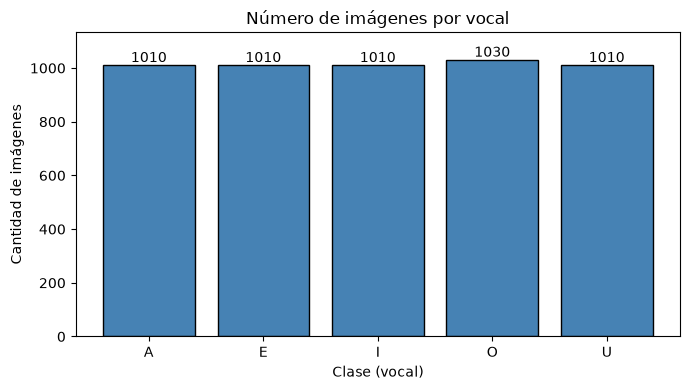

In [79]:
conteo = df["clase"].value_counts().sort_index()
print(conteo.to_string())
print("\nTotal:", conteo.sum())
print("Razón entre la clase más y menos frecuente:", round(conteo.max() / conteo.min(), 3))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(conteo.index, conteo.values, color="steelblue", edgecolor="black")
ax.set_title("Número de imágenes por vocal")
ax.set_xlabel("Clase (vocal)")
ax.set_ylabel("Cantidad de imágenes")
ax.set_ylim(0, conteo.max() * 1.1)
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

✍️ **Análisis del equipo.** Interpreten el diagrama de barras:

- ¿Las clases están balanceadas? ¿Cuál es la razón entre la más y la menos frecuente?
- ¿Qué implicaría un desbalance para las métricas (accuracy vs. precision/recall)?
- ¿Qué tratamiento sería necesario más adelante, si alguno?

_(Escriba aquí su análisis)_

## 5. Muestras aleatorias por clase

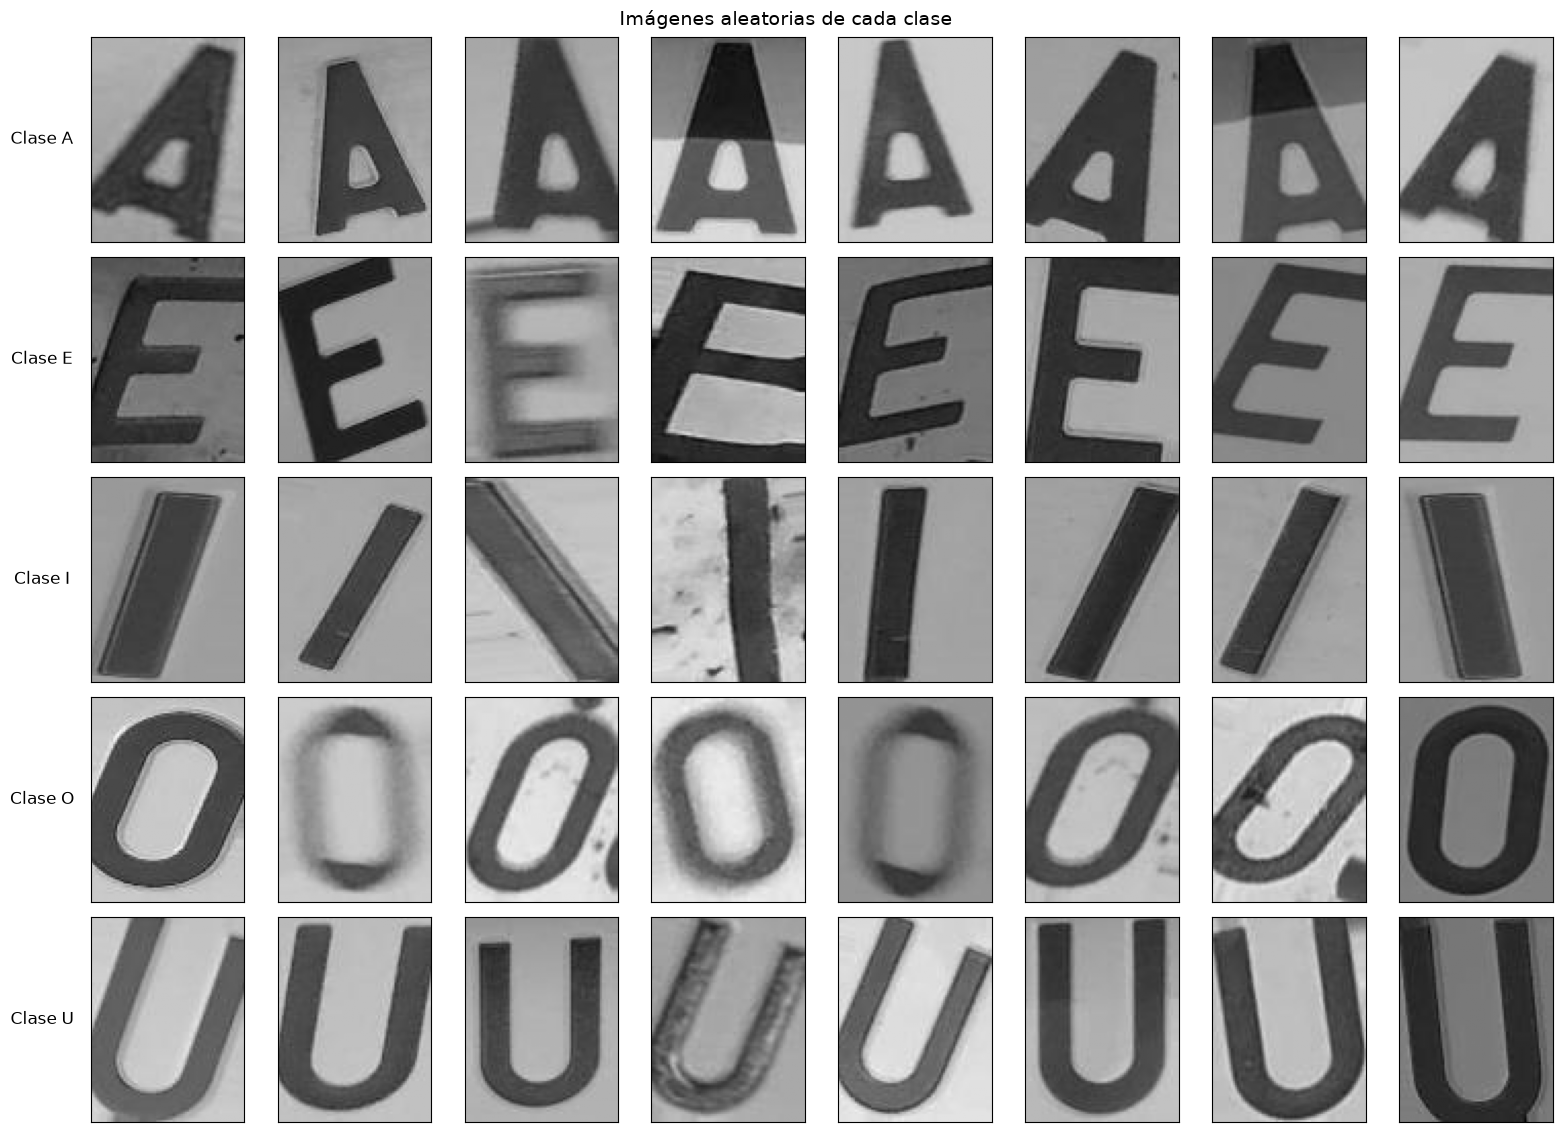

In [80]:
N_POR_CLASE = 8
rng = np.random.RandomState(7)

fig, axes = plt.subplots(len(CLASES), N_POR_CLASE, figsize=(2 * N_POR_CLASE, 2.3 * len(CLASES)))
for i, c in enumerate(CLASES):
    sub = df[df["clase"] == c]
    idx = rng.choice(len(sub), size=N_POR_CLASE, replace=False)
    for j, k in enumerate(idx):
        with Image.open(sub.iloc[k]["ruta"]) as im:
            a = np.array(im)
        ax = axes[i, j]
        ax.imshow(a, cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(f"Clase {c}", fontsize=12, rotation=0, labelpad=35, va="center")
fig.suptitle("Imágenes aleatorias de cada clase", fontsize=14)
plt.tight_layout()
plt.show()

✍️ **Análisis del equipo.** Observen la cuadrícula y describan:

Tipo de letra: son caracteres impresos o troquelados (trazo grueso y uniforme) fotografiados, no escritura a mano. El trazo es oscuro sobre fondo gris claro.

Rotación e inclinación: son muy frecuentes. La I es una barra que aparece vertical, inclinada o casi diagonal.

Recortes y escala: muchas letras están cortadas por el borde o ocupan casi toda la imagen (sobre todo E, U y O); otras tienen más margen.

Fondo e iluminación: el gris del fondo cambia de una imagen a otra, y algunas tienen bandas más oscuras o dos tonos (por ejemplo, varias A), además de sombras.

Ruido y desenfoque: hay imágenes borrosas (E y O sobre todo), con manchas o puntos (algunas I y O) y con bordes pixelados.

Posible confusión: la I, al ser una barra sin rasgos, puede confundirse con ruido o con bordes de otras letras recortadas. A y U son las que tienen formas más distintivas. No se observaron imágenes claramente mal etiquetadas en la muestra revisada.

Implicaciones: los modelos clásicos (que usan píxeles sueltos) serán sensibles a la rotación, el recorte y el fondo; por eso pueden hacer falta normalización de brillo/contraste y modelos que capturen forma (como una CNN). El aumento de datos ya incluye parte de esta variabilidad.

## 6. Dimensiones, canales y formato

Se verifican todas las imágenes del dataset (no solo una muestra): tamaño, modo de color, número de canales, tipo de dato y rango de intensidades.

In [81]:
filas = []
for ruta, clase in zip(df["ruta"], df["clase"]):
    try:
        with Image.open(ruta) as im:
            a = np.array(im)
            filas.append({
                "clase": clase,
                "ancho": im.size[0],
                "alto": im.size[1],
                "modo": im.mode,
                "canales": 1 if a.ndim == 2 else a.shape[2],
                "dtype": str(a.dtype),
                "min": int(a.min()),
                "max": int(a.max()),
                "media": float(a.mean()),
                "desv": float(a.std()),
            })
    except Exception as e:
        filas.append({"clase": clase, "ancho": np.nan, "alto": np.nan, "modo": "ERROR",
                      "canales": np.nan, "dtype": "", "min": np.nan, "max": np.nan,
                      "media": np.nan, "desv": np.nan})

info = pd.DataFrame(filas)
info["ruta"] = df["ruta"].values

print("Tamaños (ancho, alto) y frecuencia:")
print(info.groupby(["ancho", "alto"]).size().to_string())
print("\nModos de color:\n", info["modo"].value_counts().to_string())
print("\nNúmero de canales:\n", info["canales"].value_counts().to_string())
print("\nTipo de dato:\n", info["dtype"].value_counts().to_string())
print("\nFormato de archivo:\n", df["formato"].value_counts().to_string())

mismo_tamano = info[["ancho", "alto"]].drop_duplicates().shape[0] == 1
print("\n¿Todas las imágenes tienen el mismo tamaño?", mismo_tamano)

Tamaños (ancho, alto) y frecuencia:
ancho  alto
75     100     5070

Modos de color:
 modo
L    5070

Número de canales:
 canales
1    5070

Tipo de dato:
 dtype
uint8    5070

Formato de archivo:
 formato
.jpg    5070

¿Todas las imágenes tienen el mismo tamaño? True


In [82]:
resumen = info[["min", "max", "media", "desv"]].describe().round(2)
resumen

,min,max,media,desv
count,5070.00,5070.00,5070.00,5070.00
mean,27.80,192.22,124.78,50.00
std,16.91,28.23,23.03,9.93
min,0.00,119.00,56.09,22.88
25%,15.00,169.00,107.41,42.61
50%,25.00,193.00,123.89,49.67
75%,38.00,215.00,140.55,56.98
max,123.00,255.00,198.19,82.41


✍️ **Análisis del equipo.**

Sí, todas son iguales: las 5070 imágenes miden 75 × 100 píxeles (ancho × alto), están en modo L (escala de grises, 1 canal), son uint8 y tienen formato .jpg. No hay que redimensionar ni convertir canales. Como son JPEG, hay una leve compresión con pérdida.

Rango de píxeles: de 0 a 255. Se recomienda normalizar dividiendo entre 255 para llevar los valores a [0, 1] (o estandarizar), sobre todo para regresión y redes neuronales.

Representación para modelos clásicos: cada imagen se aplana en un vector de 100 × 75 = 7500 características. Es un número alto frente a 5070 ejemplos, así que podría ser útil reducir dimensionalidad (PCA) o reducir el tamaño de la imagen.

## 7. Calidad de los datos

Se revisa: imágenes corruptas, duplicados exactos (por contenido), imágenes idénticas en clases distintas, brillo/contraste atípicos y el patrón de los nombres de archivo.

In [83]:
# 1) Imágenes corruptas o ilegibles
corruptas = []
for ruta in df["ruta"]:
    try:
        with Image.open(ruta) as im:
            im.verify()
    except Exception:
        corruptas.append(ruta)
print("Imágenes corruptas:", len(corruptas))

# 2) Duplicados exactos por contenido (hash MD5)
def md5(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        h.update(f.read())
    return h.hexdigest()

df["hash"] = [md5(r) for r in df["ruta"]]
print("Archivos duplicados exactos:", int(df["hash"].duplicated().sum()))
print("Contenidos repetidos en clases distintas:", int((df.groupby("hash")["clase"].nunique() > 1).sum()))

# 3) Valores faltantes en la tabla de metadatos
print("\nValores faltantes en la tabla de metadatos:")
print(df[["ruta", "clase", "formato"]].isna().sum().to_string())

Imágenes corruptas: 0
Archivos duplicados exactos: 0
Contenidos repetidos en clases distintas: 0

Valores faltantes en la tabla de metadatos:
ruta       0
clase      0
formato    0


Imágenes con desviación estándar < 10 (poco contraste): 0
Ninguna


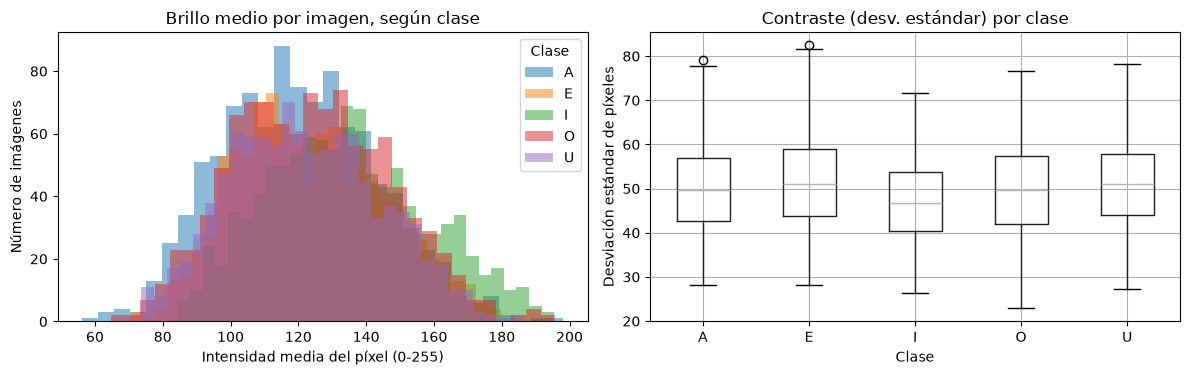

In [84]:
# 4) Imágenes casi uniformes (poco contraste) o muy oscuras/claras
UMBRAL_DESV = 10
poco_contraste = info[info["desv"] < UMBRAL_DESV]
print(f"Imágenes con desviación estándar < {UMBRAL_DESV} (poco contraste): {len(poco_contraste)}")
print(poco_contraste["clase"].value_counts().to_string() if len(poco_contraste) else "Ninguna")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c in CLASES:
    axes[0].hist(info.loc[info["clase"] == c, "media"], bins=30, alpha=0.5, label=c)
axes[0].set_title("Brillo medio por imagen, según clase")
axes[0].set_xlabel("Intensidad media del píxel (0-255)")
axes[0].set_ylabel("Número de imágenes")
axes[0].legend(title="Clase")

info.boxplot(column="desv", by="clase", ax=axes[1])
axes[1].set_title("Contraste (desv. estándar) por clase")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Desviación estándar de píxeles")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [85]:
# 5) Patrón de los nombres de archivo (el prefijo "aug" sugiere datos aumentados)
patron = re.compile(r"^aug(\d+)_(\d+)$")
nombres = df["ruta"].apply(lambda p: Path(p).stem)
coincide = nombres.apply(lambda s: bool(patron.match(s)))
print(f"Archivos que siguen el patrón 'aug<id>_<sufijo>': {coincide.sum()} de {len(df)}")

if coincide.any():
    ids = nombres[coincide].apply(lambda s: patron.match(s).group(1))
    sufijos = nombres[coincide].apply(lambda s: int(patron.match(s).group(2)))
    print("Identificadores distintos:", ids.nunique())
    print("Veces que se repite un mismo id:", dict(Counter(Counter(ids).values())))
    print("\nFrecuencia de cada sufijo:")
    print(sufijos.value_counts().sort_index().rename_axis("sufijo").to_string())

Archivos que siguen el patrón 'aug<id>_<sufijo>': 5070 de 5070
Identificadores distintos: 4810
Veces que se repite un mismo id: {1: 4550, 2: 260}

Frecuencia de cada sufijo:
sufijo
0     443
1     443
2     443
3     443
4     443
5     443
6     443
7     443
8     443
9     443
10     64
11     64
12     64
13     64
14     64
15     64
16     64
17     64
18     64
19     64


✍️ **Análisis del equipo.**

- ¿Hay imágenes corruptas, duplicadas o con contenido repetido entre clases? ¿Qué tratamiento corresponde?
- ¿Hay imágenes con poco contraste o brillo extremo? ¿Difieren entre clases?
- El prefijo `aug` en los nombres sugiere que el dataset es **aumentado**. Investiguen en la documentación cómo se generó. ¿Qué riesgo implica para dividir en entrenamiento y prueba (versiones muy parecidas de una misma imagen en ambos conjuntos)? ¿Cómo lo manejarían?

_(Escriba aquí su análisis)_

Ids que aparecen en clases distintas: 20
  Pares de clases: {'I-U': 20}
Ids repetidos dentro de una misma clase: 240
  Clase donde ocurre (ids distintos por clase): {'A': 240}


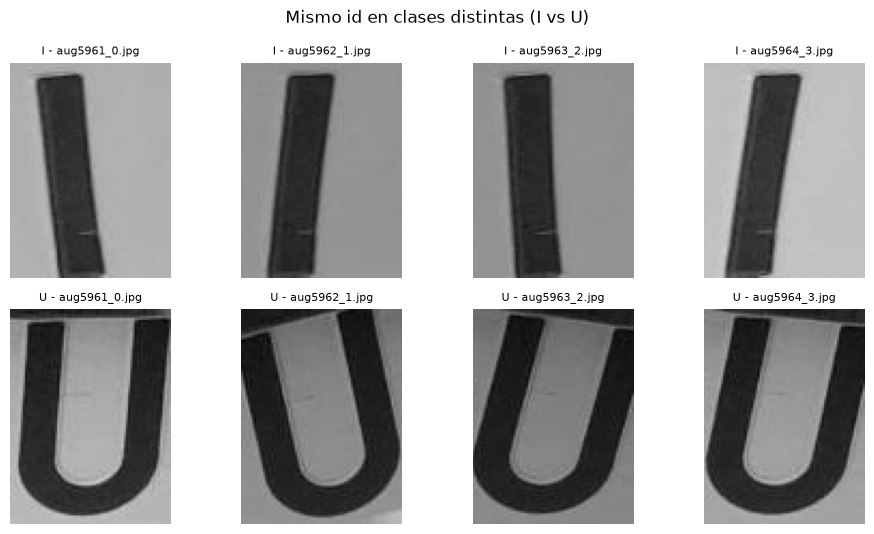

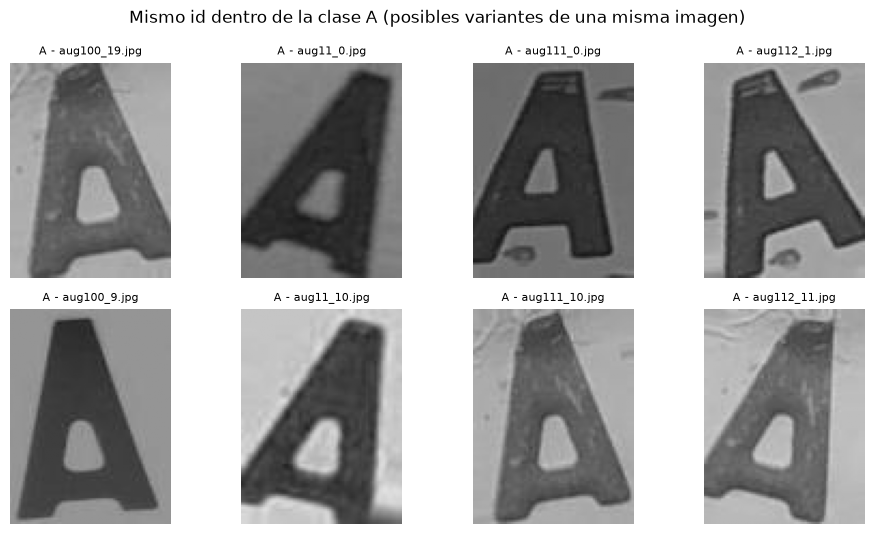

In [86]:
# 6) Ids repetidos: ¿dentro de una misma clase o entre clases distintas?
df["id"] = df["ruta"].apply(lambda p: re.match(r"aug(\d+)_", Path(p).stem).group(1))
n_clases_por_id = df.groupby("id")["clase"].nunique()
n_archivos_por_id = df.groupby("id").size()

ids_cruzados = n_clases_por_id[n_clases_por_id > 1].index.tolist()
ids_misma_clase = n_archivos_por_id[(n_archivos_por_id > 1) & (n_clases_por_id == 1)].index.tolist()
print("Ids que aparecen en clases distintas:", len(ids_cruzados))
print("  Pares de clases:", df[df["id"].isin(ids_cruzados)].groupby("id")["clase"].apply(lambda s: "-".join(sorted(s))).value_counts().to_dict())
print("Ids repetidos dentro de una misma clase:", len(ids_misma_clase))
print("  Clase donde ocurre (ids distintos por clase):", df[df["id"].isin(ids_misma_clase)].groupby("clase")["id"].nunique().to_dict())

def mostrar_pares(ids, titulo, n=4):
    fig, axes = plt.subplots(2, n, figsize=(2.4 * n, 5.4))
    for j, i in enumerate(ids[:n]):
        filas_id = df[df["id"] == i].sort_values("clase").head(2)
        for r, (_, fila) in enumerate(filas_id.iterrows()):
            with Image.open(fila["ruta"]) as im:
                axes[r, j].imshow(im, cmap="gray", vmin=0, vmax=255)
            axes[r, j].set_title(f"{fila['clase']} - {Path(fila['ruta']).name}", fontsize=8)
            axes[r, j].axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar_pares(ids_cruzados, "Mismo id en clases distintas (I vs U)")
mostrar_pares(ids_misma_clase, "Mismo id dentro de la clase A (posibles variantes de una misma imagen)")

Corruptas, duplicados y repetidos entre clases: hay 0 imágenes corruptas, 0 archivos duplicados exactos (hash MD5) y 0 contenidos idénticos en clases distintas. No hay valores faltantes en los metadatos.

Contraste y brillo: ninguna imagen tiene poco contraste (desviación estándar < 10). El brillo medio varía bastante entre imágenes (≈ 56 a 198), lo que refleja los distintos fondos; por clase es parecido, aunque la I es algo más clara (≈ 134 frente a ≈ 120–124 en las demás), porque su trazo es más delgado y ocupa menos área.

Ids repetidos: hay 4810 ids distintos para 5070 archivos. Hay 260 ids repetidos: 240 están dentro de la clase A (por ejemplo, aug375_4 y aug375_14), que probablemente son variantes de una misma imagen original; los otros 20 (ids 5961 a 5980) aparecen una vez en I y otra en U. Como se ve en la celda anterior, esos pares de I y U son letras distintas, así que se trata de una coincidencia de numeración y no de un error de etiquetado.

Riesgo para entrenamiento y prueba: al ser un dataset aumentado, versiones muy parecidas de una misma imagen pueden caer en entrenamiento y en prueba si se divide al azar, lo que inflaría las métricas (fuga de datos). Para manejarlo conviene partir agrupando por id (por ejemplo con GroupShuffleSplit o StratifiedGroupKFold) y, si se puede, confirmar en la documentación cómo se generó el aumento.

## 8. Exploración gráfica adicional

### Imagen promedio por clase y distribución de intensidades
La imagen promedio permite ver qué forma "típica" tiene cada vocal; el histograma de intensidades muestra cómo se distribuyen los valores de píxel.

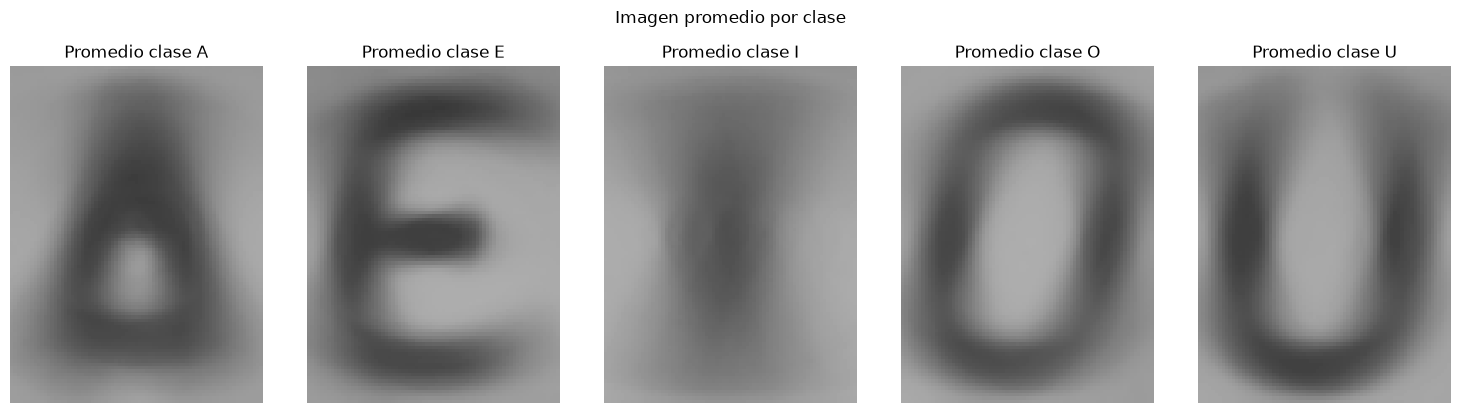

In [87]:
# Imagen promedio por clase (todas las imágenes tienen el mismo tamaño si mismo_tamano es True)
if not mismo_tamano:
    print("Las imágenes no tienen todas el mismo tamaño; se omite la imagen promedio.")
else:
    H, W = int(info["alto"].iloc[0]), int(info["ancho"].iloc[0])
    promedios = {}
    for c in CLASES:
        suma = np.zeros((H, W), dtype=np.float64)
        rutas = df.loc[df["clase"] == c, "ruta"]
        for r in rutas:
            with Image.open(r) as im:
                suma += np.array(im.convert("L"), dtype=np.float64)
        promedios[c] = suma / len(rutas)

    fig, axes = plt.subplots(1, len(CLASES), figsize=(3 * len(CLASES), 4))
    for ax, c in zip(axes, CLASES):
        ax.imshow(promedios[c], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"Promedio clase {c}")
        ax.axis("off")
    plt.suptitle("Imagen promedio por clase", y=1.02)
    plt.tight_layout()
    plt.show()

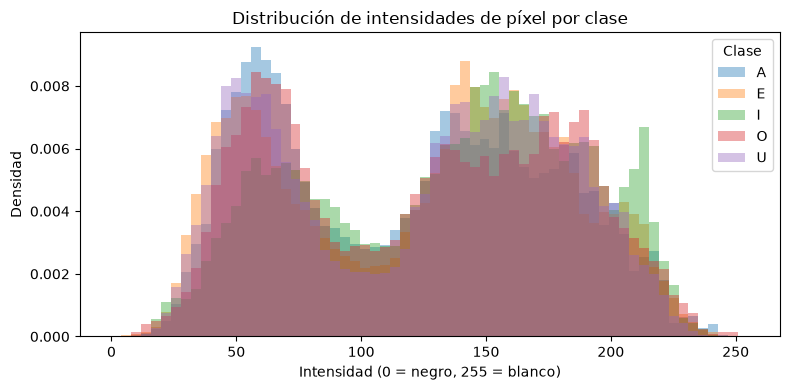

In [88]:
# Histograma de intensidades de píxel (muestra de 300 imágenes por clase)
fig, ax = plt.subplots(figsize=(8, 4))
for c in CLASES:
    sub = df[df["clase"] == c].sample(min(300, (df["clase"] == c).sum()), random_state=42)
    pix = np.concatenate([np.array(Image.open(r).convert("L")).ravel() for r in sub["ruta"]])
    ax.hist(pix, bins=64, range=(0, 255), alpha=0.4, density=True, label=c)
ax.set_title("Distribución de intensidades de píxel por clase")
ax.set_xlabel("Intensidad (0 = negro, 255 = blanco)")
ax.set_ylabel("Densidad")
ax.legend(title="Clase")
plt.tight_layout()
plt.show()

✍️ **Análisis del equipo.**

Imagen promedio: la A, la E, la O y la U conservan una silueta clara a pesar de los giros y recortes. La I es la más difusa: aparece como una franja vertical oscura en el centro, con bordes borrosos, porque sus ejemplos están muy inclinados y varían más. Esto indica que la forma de cada vocal es lo que distingue a las clases.

Parecidos entre clases: al comparar las imágenes promedio, O y U son las más parecidas (correlación ≈ 0,85), seguidas de A e I (≈ 0,68); las demás parejas están por debajo de 0,45 o son negativas. Es de esperar que O y U sean las que más se confundan.

Intensidades: los píxeles se reparten en una zona oscura (el trazo) y otra clara (el fondo), con valores intermedios por el desenfoque. Cubren todo el rango de 0 a 255 y cambian de una imagen a otra, así que conviene normalizar antes de entrenar.

## 9. Resumen cuantitativo de la inspección

In [89]:
resumen_final = pd.DataFrame({
    "Aspecto": [
        "Total de imágenes",
        "Número de clases",
        "Clases",
        "Razón clase más/menos frecuente (razón)",
        "Formatos de archivo",
        "Tamaños distintos (ancho x alto)",
        "Modos de color",
        "Canales",
        "Imágenes corruptas",
        "Duplicados exactos",
        "Contenido repetido entre clases",
        "Imágenes con poco contraste",
    ],
    "Valor": [
        len(df),
        len(CLASES),
        ", ".join(CLASES),
        round(conteo.max() / conteo.min(), 3),
        ", ".join(df["formato"].unique()),
        "; ".join(f"{int(a)}x{int(b)}" for a, b in info[["ancho", "alto"]].drop_duplicates().values),
        ", ".join(info["modo"].unique()),
        ", ".join(str(int(x)) for x in info["canales"].dropna().unique()),
        len(corruptas),
        int(df["hash"].duplicated().sum()),
        int((df.groupby("hash")["clase"].nunique() > 1).sum()),
        len(poco_contraste),
    ],
})
resumen_final

,Aspecto,Valor
0,Total de imágenes,5070
1,Número de clases,5
2,Clases,"A, E, I, O, U"
3,Razón clase más/menos frecuente (razón),1.02
4,Formatos de archivo,.jpg
5,Tamaños distintos (ancho x alto),75x100
6,Modos de color,L
7,Canales,1
8,Imágenes corruptas,0
9,Duplicados exactos,0


## 10. Tratamientos propuestos para etapas posteriores

✍️ **Análisis del equipo.** Con base en los hallazgos anteriores, justifiquen qué tratamiento podría ser necesario más adelante (por ejemplo: normalización de píxeles, aplanado de imágenes para los modelos clásicos, partición estratificada entre entrenamiento y prueba, manejo de posibles imágenes casi duplicadas por el aumento de datos, reducción de dimensionalidad, etc.).

| Hallazgo | Evidencia (gráfica/tabla) | Tratamiento propuesto | Justificación |
|---|---|---|---|
| _(complete)_ | | | |

## 11. Preparación de las imágenes   

### 11.1 Homogenización
Todas las imágenes deben tener el mismo tamaño para poder representarlas como vectores de igual longitud.

In [90]:
# Tamaño objetivo (ancho, alto). Se usa el tamaño original del dataset.
ANCHO, ALTO = 75, 100

imgs_homog = []
n_redimensionadas = 0

for ruta in df["ruta"]:
    with Image.open(ruta) as im:
        im = im.copy()
    if im.size != (ANCHO, ALTO):          # 1) se revisa el tamaño original
        n_redimensionadas += 1            # 2) se cuenta
        im = im.resize((ANCHO, ALTO), Image.BILINEAR)   # 3) se redimensiona
    imgs_homog.append(im)

print("Imágenes procesadas:", len(imgs_homog))
print("Imágenes que hubo que redimensionar:", n_redimensionadas)
print("Tamaños finales:", pd.Series([im.size for im in imgs_homog]).value_counts().to_dict())
print("Modos:", pd.Series([im.mode for im in imgs_homog]).value_counts().to_dict())

Imágenes procesadas: 5070
Imágenes que hubo que redimensionar: 0
Tamaños finales: {(75, 100): 5070}
Modos: {'L': 5070}


### 11.2 Conversión a escala de grises

In [91]:
imgs_gris = [im.convert("L") for im in imgs_homog]

# Arreglo final: (n_imágenes, alto, ancho), valores 0-255
X_img = np.stack([np.array(im, dtype=np.uint8) for im in imgs_gris])
y = df["clase"].values

print("Forma de X_img:", X_img.shape, "| tipo:", X_img.dtype)
print("Rango de píxeles:", X_img.min(), "-", X_img.max())
print("Clases en y:", np.unique(y))

Forma de X_img: (5070, 100, 75) | tipo: uint8
Rango de píxeles: 0 - 255
Clases en y: ['A' 'E' 'I' 'O' 'U']


### 11.2 Comparacion de Imagenes

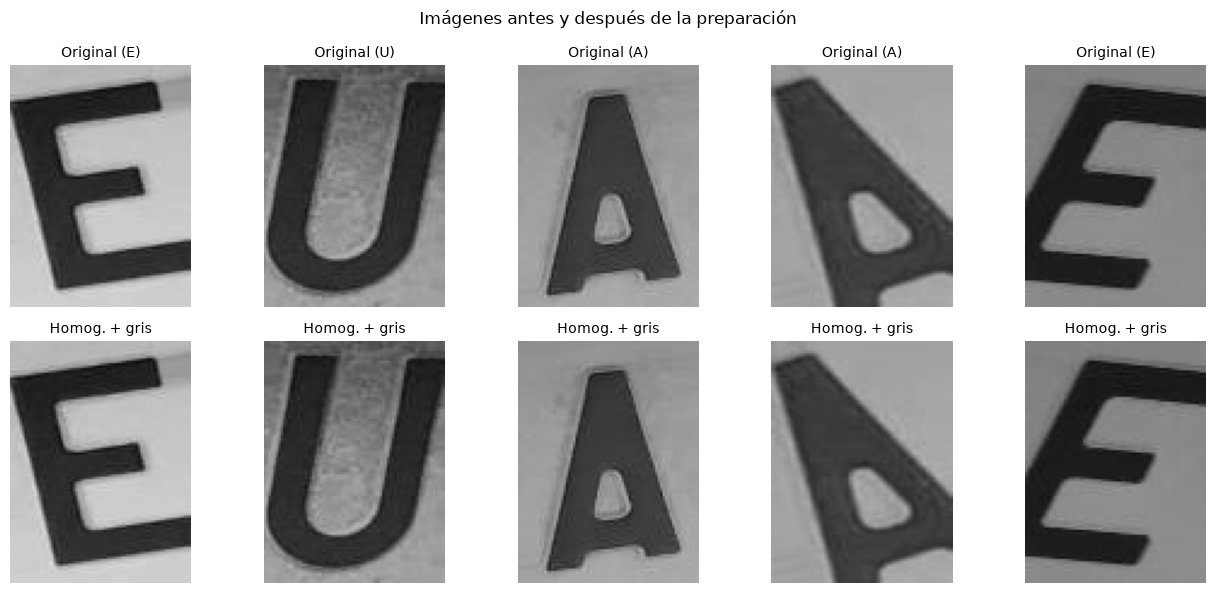

In [92]:

idx = np.random.RandomState(None).choice(len(df), 5, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for j, k in enumerate(idx):
    with Image.open(df.iloc[k]["ruta"]) as im:
        axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"Original ({df.iloc[k]['clase']})", fontsize=10)
    axes[1, j].imshow(X_img[k], cmap="gray", vmin=0, vmax=255)
    axes[1, j].set_title("Homog. + gris", fontsize=10)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("Imágenes antes y después de la preparación")
plt.tight_layout()
plt.show()

### 11.3 Flattening

Forma antes: (5070, 100, 75)
Forma después: (5070, 7500)
¿Reversible? True

Imagen mostrada: índice 1610 | archivo aug451_0.jpg | clase A


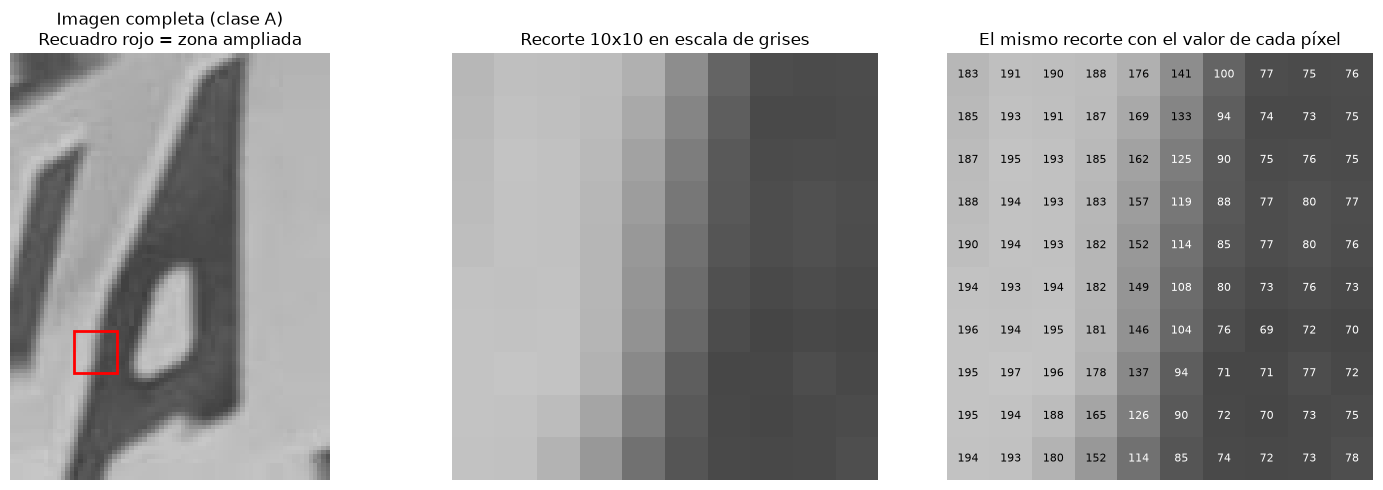

Matriz del recorte: (10, 10) -> vector aplanado: (100,)
Primeros 20 valores del vector: [183 191 190 188 176 141 100  77  75  76 185 193 191 187 169 133  94  74
  73  75]
Imagen completa: (100, 75) -> vector: (7500,)


In [93]:
# ---------- Flattening: de matriz de píxeles a vector ----------
# Cada imagen (100 x 75) se convierte en un vector de 7500 valores
X_flat = X_img.reshape(len(X_img), -1)

print("Forma antes:", X_img.shape)
print("Forma después:", X_flat.shape)
print("¿Reversible?", np.array_equal(X_flat[0].reshape(ALTO, ANCHO), X_img[0]))

# ---------- Visualización del flattening en una imagen ----------
k = None   # None = imagen aleatoria en cada ejecución; o un número (0 a len(X_img)-1) para fijarla
T = 10     # tamaño (T x T) del recorte que se amplía

if k is None:
    k = int(np.random.randint(len(X_img)))
print(f"\nImagen mostrada: índice {k} | archivo {df.loc[k, 'ruta'].name} | clase {df.loc[k, 'clase']}")

# Se busca la zona de T x T con más contraste (donde el trazo cruza el fondo)
f0, c0 = max(
    ((f, c) for f in range(0, ALTO - T + 1, 5) for c in range(0, ANCHO - T + 1, 5)),
    key=lambda p: X_img[k, p[0]:p[0]+T, p[1]:p[1]+T].std(),
)
recorte = X_img[k, f0:f0+T, c0:c0+T]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(X_img[k], cmap="gray", vmin=0, vmax=255)
axes[0].add_patch(plt.Rectangle((c0-0.5, f0-0.5), T, T, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title(f"Imagen completa (clase {df.loc[k, 'clase']})\nRecuadro rojo = zona ampliada")
axes[0].axis("off")

axes[1].imshow(recorte, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Recorte {T}x{T} en escala de grises")
axes[1].axis("off")

axes[2].imshow(recorte, cmap="gray", vmin=0, vmax=255)
for i in range(T):
    for j in range(T):
        v = int(recorte[i, j])
        axes[2].text(j, i, str(v), ha="center", va="center", fontsize=8,
                     color="white" if v < 128 else "black")
axes[2].set_title("El mismo recorte con el valor de cada píxel")
axes[2].axis("off")
plt.tight_layout()
plt.show()

vec = recorte.reshape(-1)
print("Matriz del recorte:", recorte.shape, "-> vector aplanado:", vec.shape)
print("Primeros 20 valores del vector:", vec[:20])
print("Imagen completa:", X_img[k].shape, "-> vector:", X_flat[k].shape)

### 11.4 Mapa de correlación

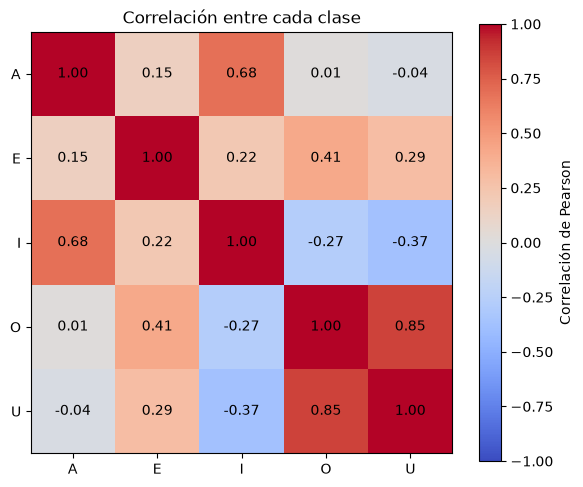

In [94]:
# Correlación entre las imágenes promedio de cada clase
matriz = np.array([promedios[c].ravel() for c in CLASES])
corr = pd.DataFrame(np.corrcoef(matriz), index=CLASES, columns=CLASES)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(CLASES))); ax.set_xticklabels(CLASES)
ax.set_yticks(range(len(CLASES))); ax.set_yticklabels(CLASES)
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre cada clase")
plt.tight_layout()
plt.show()

✍️ **Análisis del equipo.**

O y U son las más parecidas (0,85), y A e I les siguen (0,68).
Las demás parejas son bajas, o negativas (I con O: −0,27; I con U: −0,37).

Piensen qué implica: ¿qué vocales esperan que el modelo confunda más? Esa respuesta la vamos a comprobar más adelante con la matriz de confusión.

Aclaracion: No es la correlación entre cada píxel (serían 7500 × 7500 valores, ilegible), sino entre las imágenes promedio de las 5 clases. Por eso el mapa es de 5×5.

### 11.5 Partición y normalización

X_flat: (5070, 7500) | df: (5070, 5)
Imágenes originales (grupos): 443

Entrenamiento: 4040 (80%) | Prueba: 1030 (20%)
Forma de X_train: (4040, 7500) | X_test: (1030, 7500)
Rango tras normalizar: 0.0 a 1.0
Grupos compartidos entre train y test: 0


,Entrenamiento,Prueba,Total,% entrenamiento,% prueba,Grupos (originales)
Vocal,,,,,,
A,810,200,1010,80%,20%,77
E,790,220,1010,78%,22%,90
I,810,200,1010,80%,20%,74
O,820,210,1030,80%,20%,102
U,810,200,1010,80%,20%,100
TOTAL,4040,1030,5070,80%,20%,443


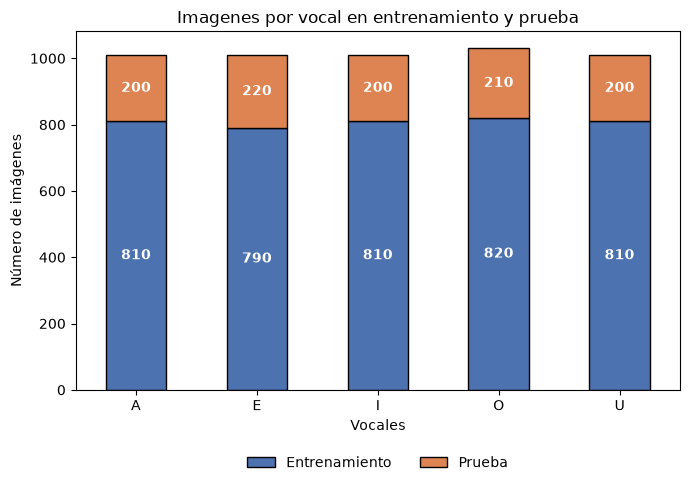

In [95]:
import re
from sklearn.model_selection import train_test_split

# Comprobación: X_flat y df deben estar alineados (fila i = imagen i)
assert X_flat.shape[0] == len(df), "X_flat y df tienen distinto número de filas"
print("X_flat:", X_flat.shape, "| df:", df.shape)

# ---------------- PARÁMETROS ----------------
PORC_TEST = 0.20       # 20 % para prueba (80 % para entrenamiento)
RANDOM_STATE = 42
# --------------------------------------------

# 1) Grupo = imagen original (clase + id - sufijo).
#    Cada original tiene 10 o 20 variantes (imágenes aumentadas).
num = df["ruta"].apply(lambda p: tuple(map(int, re.match(r"aug(\d+)_(\d+)", p.stem).groups())))
df["grupo"] = df["clase"] + "_" + num.apply(lambda t: str(t[0] - t[1]))

# 2) Una fila por imagen original, con su clase
originales = df.drop_duplicates("grupo")[["grupo", "clase"]].reset_index(drop=True)
print("Imágenes originales (grupos):", len(originales))

# 3) train_test_split sobre las ORIGINALES, estratificado por clase
g_train_u, g_test_u = train_test_split(
    originales["grupo"],
    test_size=PORC_TEST,
    random_state=RANDOM_STATE,
    stratify=originales["clase"],
)

# 4) Cada variante va al mismo conjunto que su original
es_test = df["grupo"].isin(g_test_u).values
idx_train = np.where(~es_test)[0]
idx_test = np.where(es_test)[0]

y = df["clase"].values
grupos = df["grupo"].values

# 5) Normalización (÷255): los píxeles pasan de 0-255 a 0-1
X_train = X_flat[idx_train] / 255.0
X_test = X_flat[idx_test] / 255.0
y_train, y_test = y[idx_train], y[idx_test]
g_train = grupos[idx_train]   # se usará en GridSearchCV (parámetro groups)

# 6) Verificación
total = len(y)
print(f"\nEntrenamiento: {len(idx_train)} ({len(idx_train)/total:.0%}) | Prueba: {len(idx_test)} ({len(idx_test)/total:.0%})")
print("Forma de X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Rango tras normalizar:", X_train.min(), "a", X_train.max())
print("Grupos compartidos entre train y test:", len(set(grupos[idx_train]) & set(grupos[idx_test])))


# ---------- Tabla del balance entrenamiento / prueba ----------
tabla = pd.DataFrame({
    "Entrenamiento": pd.Series(y_train).value_counts(),
    "Prueba": pd.Series(y_test).value_counts(),
}).sort_index()
tabla["Total"] = tabla["Entrenamiento"] + tabla["Prueba"]
tabla["% entrenamiento"] = (tabla["Entrenamiento"] / tabla["Total"] * 100).round(1)
tabla["% prueba"] = (tabla["Prueba"] / tabla["Total"] * 100).round(1)
tabla["Grupos (originales)"] = df.groupby("clase")["grupo"].nunique()
tabla.index.name = "Vocal"

# Fila de totales
tot = tabla[["Entrenamiento", "Prueba", "Total", "Grupos (originales)"]].sum()
tabla.loc["TOTAL"] = [tot["Entrenamiento"], tot["Prueba"], tot["Total"],
                      round(tot["Entrenamiento"] / tot["Total"] * 100, 1),
                      round(tot["Prueba"] / tot["Total"] * 100, 1),
                      tot["Grupos (originales)"]]
tabla = tabla.astype({"Entrenamiento": int, "Prueba": int, "Total": int, "Grupos (originales)": int})

# Vista con porcentajes redondeados y con el signo %
tabla_vista = tabla.copy()
for col in ["% entrenamiento", "% prueba"]:
    tabla_vista[col] = tabla_vista[col].round(0).astype(int).astype(str) + "%"

display(tabla_vista)   # si falla, use print(tabla_vista)

# ---------- Gráfica ----------
cuentas = tabla.drop(index="TOTAL")[["Entrenamiento", "Prueba"]]
ax = cuentas.plot(kind="bar", stacked=True, figsize=(7, 5),
                  color=["#4C72B0", "#DD8452"], edgecolor="black")
for cont in ax.containers:
    ax.bar_label(cont, label_type="center", color="white", fontweight="bold")
ax.set_title("Imagenes por vocal en entrenamiento y prueba")
ax.set_xlabel("Vocales")
ax.set_ylabel("Número de imágenes")
plt.xticks(rotation=0)
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.tight_layout()
plt.show()



### 12 Aplicando PCA

Número total de variables (píxeles):  7500
Variables constantes (varianza cero): 0
Variables con varianza menor a 0.01:  0


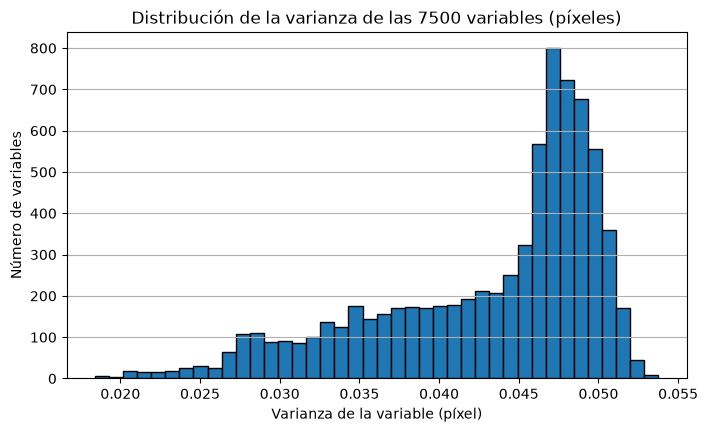

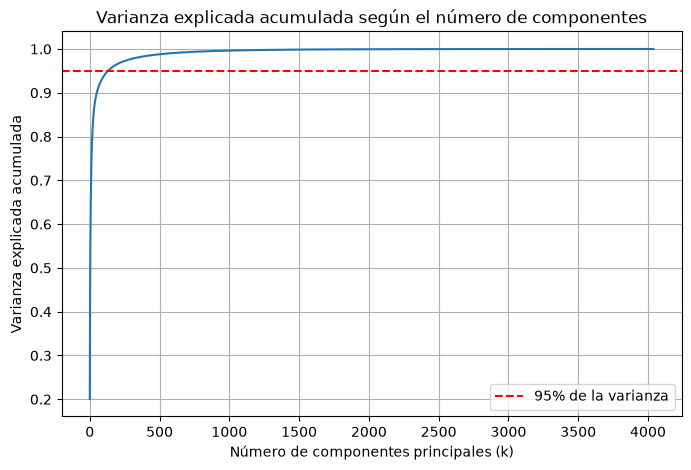

Varianza capturada por las primeras   10 componentes: 0.6954
Varianza capturada por las primeras   20 componentes: 0.8137
Varianza capturada por las primeras   50 componentes: 0.8988
Varianza capturada por las primeras  100 componentes: 0.9377
Varianza capturada por las primeras  132 componentes: 0.9504
Varianza capturada por las primeras  200 componentes: 0.9659
Varianza capturada por las primeras  300 componentes: 0.9775
Varianza capturada por las primeras  500 componentes: 0.9880
Varianza capturada por las primeras 1000 componentes: 0.9963
Componentes necesarios para explicar el 95% de la varianza: 131
Dimensión original de entrenamiento:  (4040, 7500)
Dimensión reducida de entrenamiento:  (4040, 131)
Dimensión reducida de prueba:         (1030, 131)


In [96]:
# Varianza de cada píxel (variable) a lo largo de las imágenes de entrenamiento
varianza_pixeles = X_train.var(axis=0)

n_total = X_train.shape[1]
n_constantes = (varianza_pixeles == 0).sum()
n_casi_constantes = (varianza_pixeles < 0.01).sum()

print("Número total de variables (píxeles):  %d" % n_total)
print("Variables constantes (varianza cero): %d" % n_constantes)
print("Variables con varianza menor a 0.01:  %d" % n_casi_constantes)

plt.figure(figsize=(8, 4.5))
plt.hist(varianza_pixeles, bins=40, edgecolor='black')
plt.xlabel('Varianza de la variable (píxel)')
plt.ylabel('Número de variables')
plt.title('Distribución de la varianza de las 7500 variables (píxeles)')
plt.grid(True, axis='y')
plt.show()


from sklearn.decomposition import PCA

pca_completo = PCA()
pca_completo.fit(X_train)

# Varianza explicada acumulada: cuánto explican las primeras k componentes en conjunto
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(varianza_acumulada)
plt.axhline(y=0.95, color='red', linestyle='--', label='95% de la varianza')
plt.xlabel('Número de componentes principales (k)')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada según el número de componentes')
plt.legend()
plt.grid(True)
plt.show()

# Porcentaje de varianza capturada por las primeras k componentes
for k in [10, 20, 50, 100, 132, 200, 300, 500, 1000]:
    print('Varianza capturada por las primeras %4d componentes: %.4f'
          % (k, varianza_acumulada[k - 1]))
 # PCA que conserva el 95% de la varianza, ajustado SOLO con entrenamiento
pca = PCA(n_components=0.95)
X_train_PCA = pca.fit_transform(X_train)

# transform (SIN fit): la prueba se proyecta con el PCA ya ajustado en entrenamiento
X_test_PCA = pca.transform(X_test)

print("Componentes necesarios para explicar el 95%% de la varianza: %d" % pca.n_components_)
print("Dimensión original de entrenamiento: ", X_train.shape)
print("Dimensión reducida de entrenamiento: ", X_train_PCA.shape)
print("Dimensión reducida de prueba:        ", X_test_PCA.shape)

IMAGEN 1 - Varianza por píxel 0 variables constantes y 0 con varianza menor a 0,01. Las varianzas van de ≈0,019 a ≈0,053, y la mayoría se concentra entre 0,045 y 0,050, con una cola hacia valores menores. Esto contrasta con MNIST, donde muchos píxeles de los bordes valen siempre 0. Aquí ningún píxel se puede descartar de entrada, porque los fondos, el brillo y las rotaciones cambian toda la imagen. La causa exacta de la cola de varianzas bajas no la sé; si quieren afirmarla, tendrían que graficar la varianza como imagen de 100×75 para ver qué zona es.


IMAGEN 2 - Varianza acumulada La curva sube casi vertical y se aplana: unas pocas componentes capturan la mayor parte de la información. Con 10 componentes ya hay 69,5 %, con 100 hay 93,8 %, y con 131 se llega al 95 %. El eje llega solo hasta ≈4040 porque PCA no puede tener más componentes que el menor entre el número de imágenes y el de variables (aquí 4040 imágenes de entrenamiento).

PCA al 95 %. Pasan de 7500 variables a 131, es decir, menos del 2 %.

### 12.1 Sección de inspección

Matriz de píxeles: (5070, 7500)


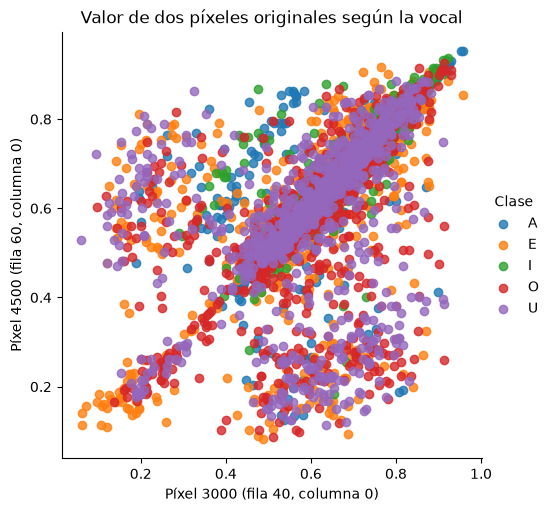

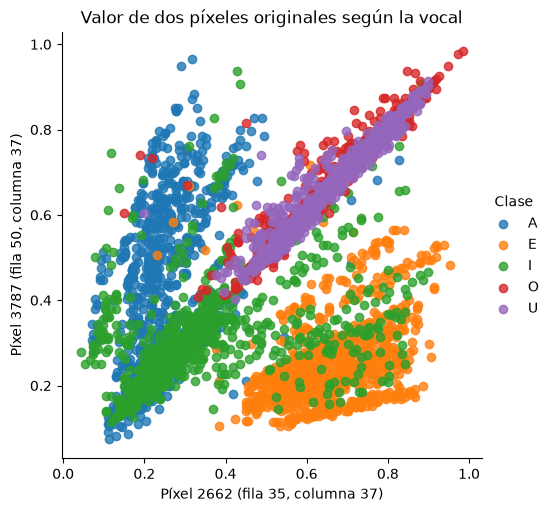

In [97]:
import seaborn as sns

# Matriz de píxeles de TODAS las imágenes (una fila por imagen, 7500 columnas, valores 0-1)
X_todo = np.stack([np.array(Image.open(p).convert("L"), dtype=np.uint8).reshape(-1)
                   for p in df["ruta"]]) / 255.0
y_todo = df["clase"].values
print("Matriz de píxeles:", X_todo.shape)

def dispersion_pixeles(X, y, pix1, pix2):
    """Dispersión de dos píxeles originales, coloreada por clase."""
    temp = pd.DataFrame({"v1": X[:, pix1], "v2": X[:, pix2], "Clase": y})
    sns.lmplot(x="v1", y="v2", hue="Clase", data=temp, fit_reg=False,
               hue_order=sorted(set(y)))
    ax = plt.gca()
    f1, c1 = divmod(pix1, ANCHO)
    f2, c2 = divmod(pix2, ANCHO)
    ax.set_xlabel(f"Píxel {pix1} (fila {f1}, columna {c1})")
    ax.set_ylabel(f"Píxel {pix2} (fila {f2}, columna {c2})")
    ax.set_title("Valor de dos píxeles originales según la vocal")
    plt.show()

# Dos píxeles del borde izquierdo
dispersion_pixeles(X_todo, y_todo, 3000, 4500)

# Dos píxeles del centro de la imagen (fila 35 y fila 50, columna 37)
dispersion_pixeles(X_todo, y_todo, 2662, 3787)

Observacion: Se observa que la posición importa: los píxeles del borde izquierdo no separan las vocales, pues todas las clases se mezclan en una misma banda, mientras que los de la columna central ya forman grupos, con A, E y el conjunto O–U ocupando zonas distintas. Aun así, O y U se superponen y A e I quedan cerca, lo que coincide con la correlación de sus imágenes promedio.

### 12.2 Dispersión y reconstrucción

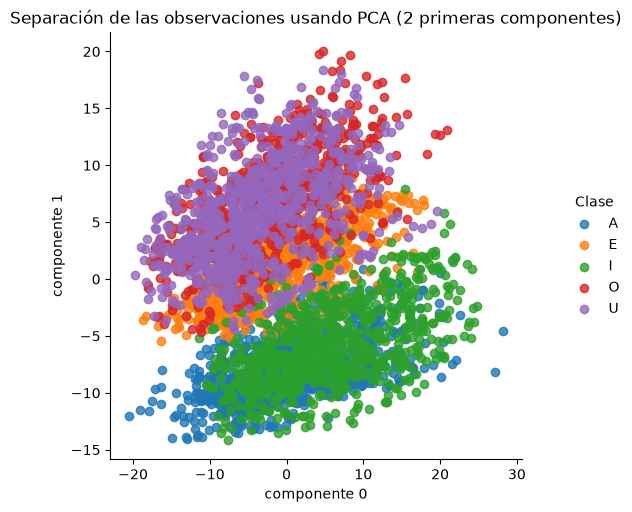

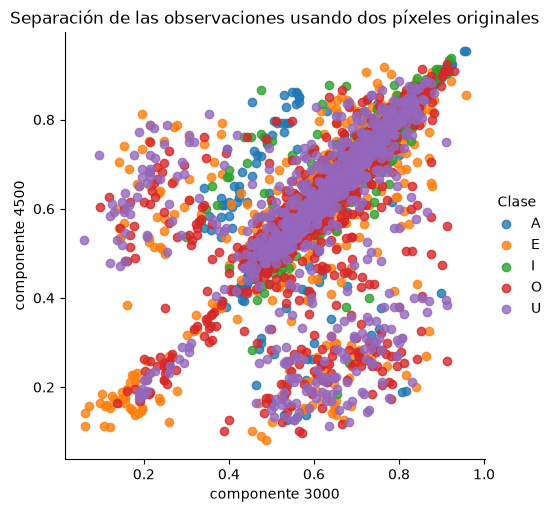

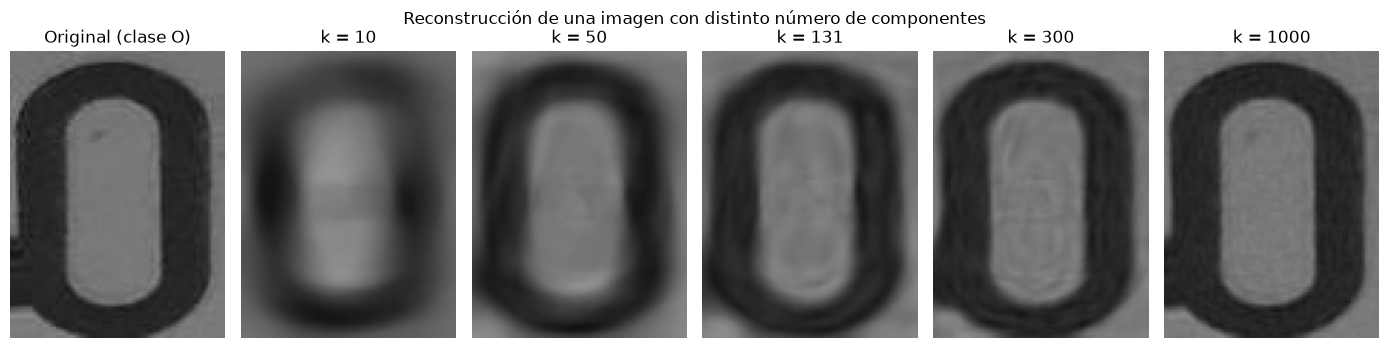

In [98]:
import seaborn as sns

def grafico_dispersion(X, y, nombre_algoritmo, col1, col2):
    """Grafica dos columnas de X coloreando cada punto según su clase y."""
    temp = pd.DataFrame(data=X[:, [col1, col2]], columns=["v1", "v2"])
    temp["Clase"] = y
    sns.lmplot(x="v1", y="v2", hue="Clase", data=temp, fit_reg=False,
               hue_order=sorted(set(y)))
    ax = plt.gca()
    ax.set_xlabel(f"componente {col1}")
    ax.set_ylabel(f"componente {col2}")
    ax.set_title("Separación de las observaciones usando " + nombre_algoritmo)
    plt.show()

# Las dos primeras componentes principales
grafico_dispersion(X_train_PCA, y_train, "PCA (2 primeras componentes)", 0, 1)

# En contraste: dos píxeles originales cualesquiera (columnas 3000 y 4500)
grafico_dispersion(X_train, y_train, "dos píxeles originales", 3000, 4500)

# ---------- Reconstrucción de una imagen con distinto número de componentes ----------
ejemplo = 0
valores_k = [10, 50, 131, 300, 1000]

# Proyectamos el ejemplo sobre todas las componentes del PCA completo
z = pca_completo.transform(X_train[[ejemplo]])[0]

fig, ejes = plt.subplots(1, len(valores_k) + 1, figsize=(14, 3.5))
ejes[0].imshow(X_train[ejemplo].reshape(ALTO, ANCHO), cmap="gray", vmin=0, vmax=1)
ejes[0].set_title(f"Original (clase {y_train[ejemplo]})")
ejes[0].axis("off")

for eje, k in zip(ejes[1:], valores_k):
    x_rec = pca_completo.mean_ + z[:k] @ pca_completo.components_[:k, :]
    eje.imshow(x_rec.reshape(ALTO, ANCHO), cmap="gray", vmin=0, vmax=1)
    eje.set_title("k = %d" % k)
    eje.axis("off")

plt.suptitle("Reconstrucción de una imagen con distinto número de componentes")
plt.tight_layout()
plt.show()

Observacion:
se observa una separación parcial entre las vocales: A e I quedan en la parte inferior de la gráfica y E, O y U en la superior, mientras que O y U se superponen casi por completo.

### 13 Regresion Multivariada

### 13.1 Imports y comprobación de datos

In [99]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import (confusion_matrix, make_scorer, classification_report,
                             precision_score, recall_score,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, cross_val_predict, StratifiedGroupKFold, GridSearchCV

faltan = [n for n in ["X_train", "y_train", "X_test", "y_test", "g_train", "X_train_PCA", "X_test_PCA"] if n not in globals()]
if faltan:
    raise NameError(f"Faltan estas variables de tu notebook: {faltan}. "
                    "Ejecuta primero las celdas de carga de datos y partición (sección 11.5).")

y_arr = np.asarray(y_train)
CLASES = list(CLASES) if "CLASES" in globals() else sorted(np.unique(y_arr).tolist())

cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
particiones = list(cv_grupos.split(X_train, y_train, groups=g_train))

### Modelo de regresión sobre etiquetas one-hot, especificidad y scorers

In [100]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression

class RegresionLinealClasificador(ClassifierMixin, BaseEstimator):
    """Regresión lineal / Ridge / Lasso sobre etiquetas one-hot; predice la clase de mayor salida."""
    def __init__(self, modelo="ridge", alpha=1.0, max_iter=10000):
        self.modelo = modelo
        self.alpha = alpha
        self.max_iter = max_iter

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        Y = (y[:, None] == self.classes_[None, :]).astype(float)
        if self.modelo == "lineal":
            self.reg_ = LinearRegression()
        elif self.modelo == "ridge":
            self.reg_ = Ridge(alpha=self.alpha)
        elif self.modelo == "lasso":
            self.reg_ = Lasso(alpha=self.alpha, max_iter=self.max_iter)
        else:
            raise ValueError(f"modelo desconocido: {self.modelo!r} (use 'lineal', 'ridge' o 'lasso')")
        self.reg_.fit(X, Y)
        return self

    def decision_function(self, X):
        return self.reg_.predict(X)

    def predict(self, X):
        return self.classes_[self.decision_function(X).argmax(axis=1)]


def especificidad_macro(y_true, y_pred, labels=tuple(CLASES)):
    cm_ = confusion_matrix(y_true, y_pred, labels=list(labels))
    esp_ = []
    for k in range(len(labels)):
        tp = cm_[k, k]
        fp = cm_[:, k].sum() - tp
        fn = cm_[k, :].sum() - tp
        tn = cm_.sum() - tp - fp - fn
        esp_.append(tn / (tn + fp))
    return np.mean(esp_)

# Ridge/Lasso no dan probabilidades -> sin log loss
SCORING_REG = {
    "accuracy":      "accuracy",
    "precision":     make_scorer(precision_score, average="macro", zero_division=0),
    "recall":        make_scorer(recall_score,    average="macro", zero_division=0),
    "especificidad": make_scorer(especificidad_macro),
}
# Para modelos con predict_proba (regresión logística, árbol, RF, MLP, DNN)
SCORING_CLF = {**SCORING_REG, "log_loss": "neg_log_loss"}

### Resúmenes y matriz de confusión

In [101]:
def resumir_cv(cv_res, scoring):
    filas = {}
    for m in scoring:
        for conj, pref in [("validación", "test"), ("entrenamiento", "train")]:
            v = cv_res[f"{pref}_{m}"]
            if m == "log_loss":
                v = -v
            filas.setdefault(m, {})[f"{conj} (media)"] = v.mean()
            filas[m][f"{conj} (std)"] = v.std()
    tabla = pd.DataFrame(filas).T
    tabla.loc["FPR"] = [1 - tabla.loc["especificidad", "validación (media)"],
                        tabla.loc["especificidad", "validación (std)"],
                        1 - tabla.loc["especificidad", "entrenamiento (media)"],
                        tabla.loc["especificidad", "entrenamiento (std)"]]
    return tabla.round(4)


def metricas_por_clase(y_real, y_pred, clases):
    cm_ = confusion_matrix(y_real, y_pred, labels=clases)
    rep_ = pd.DataFrame(classification_report(
        y_real, y_pred, labels=clases, output_dict=True, zero_division=0
    )).T.loc[clases, ["precision", "recall", "f1-score", "support"]]
    esp_, fpr_ = [], []
    for k in range(len(clases)):
        tp = cm_[k, k]; fp = cm_[:, k].sum() - tp
        fn = cm_[k, :].sum() - tp; tn = cm_.sum() - tp - fp - fn
        esp_.append(tn / (tn + fp)); fpr_.append(fp / (fp + tn))
    rep_["especificidad"] = esp_
    rep_["FPR"] = fpr_
    return rep_, cm_


def graficar_matriz_confusion(cm_, clases, titulo):
    pct = cm_ / cm_.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(clases)):
        for j in range(len(clases)):
            ax.text(j, i, f"{cm_[i, j]}\n({pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=10,
                    fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(len(clases))); ax.set_xticklabels(clases)
    ax.set_yticks(range(len(clases))); ax.set_yticklabels(clases)
    ax.set_xlabel("Vocal predicha"); ax.set_ylabel("Vocal real")
    ax.set_title(titulo, fontsize=12, pad=12)
    fig.colorbar(im, ax=ax, label="Proporción de la vocal real")
    plt.tight_layout(); plt.show()


def mostrar(obj):
    try:
        display(obj)
    except NameError:
        print(obj)

### Evaluación por validación cruzada y tabla comparativa

In [102]:
def evaluar_modelo(nombre, modelo, X, y, cv, scoring, clases):
    """Validación cruzada + matriz de confusión + métricas por clase."""
    cv_res = cross_validate(modelo, X, y, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-1)
    resumen = resumir_cv(cv_res, scoring)
    y_pred = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)
    rep_, cm_ = metricas_por_clase(y, y_pred, clases)
    print(f"===== {nombre}: métricas (validación cruzada) =====")
    print(resumen)
    graficar_matriz_confusion(cm_, clases, f"Matriz de confusión – {nombre} (validación cruzada)")
    print(f"\n{nombre}: métricas por clase")
    mostrar(rep_.round(4))
    return {"cv": cv_res, "resumen": resumen, "cm": cm_, "rep": rep_, "y_pred": y_pred}


def tabla_comparativa(resultados, metricas=("accuracy", "precision", "recall",
                                            "especificidad", "FPR", "log_loss")):
    filas = {}
    for nombre, r in resultados.items():
        fila = {}
        for m in metricas:
            if m in r["resumen"].index:
                med = r["resumen"].loc[m, "validación (media)"]
                std = r["resumen"].loc[m, "validación (std)"]
                fila[m] = f"{med:.4f} ± {std:.4f}"
            else:
                fila[m] = "N/A"
        filas[nombre] = fila
    return pd.DataFrame(filas).T

def obtener_coef(modelo):
    ultimo = modelo.steps[-1][1] if isinstance(modelo, Pipeline) else modelo
    return ultimo.reg_.coef_ if hasattr(ultimo, "reg_") else ultimo.coef_


def resumen_coeficientes(modelos):
    filas = []
    for nombre, m in modelos:
        c = obtener_coef(m)
        filas.append({"Modelo": nombre,
                      "Coeficientes totales": c.size,
                      "Distintos de cero": int((np.abs(c) > 1e-12).sum()),
                      "Iguales a cero": int((np.abs(c) <= 1e-12).sum()),
                      "Promedio de |coef|": np.abs(c).mean()})
    return pd.DataFrame(filas).set_index("Modelo").round(5)

### 13.2 Modelos Base: lineal, Ridge y Lasso

### Regresión logística

===== Regresión logística base: métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.9700            0.0075                 1.0000               0.0000
precision                  0.9727            0.0062                 1.0000               0.0000
recall                     0.9705            0.0075                 1.0000               0.0000
especificidad              0.9925            0.0019                 1.0000               0.0000
log_loss                   0.1221            0.0510                 0.0021               0.0001
FPR                        0.0075            0.0019                 0.0000               0.0000


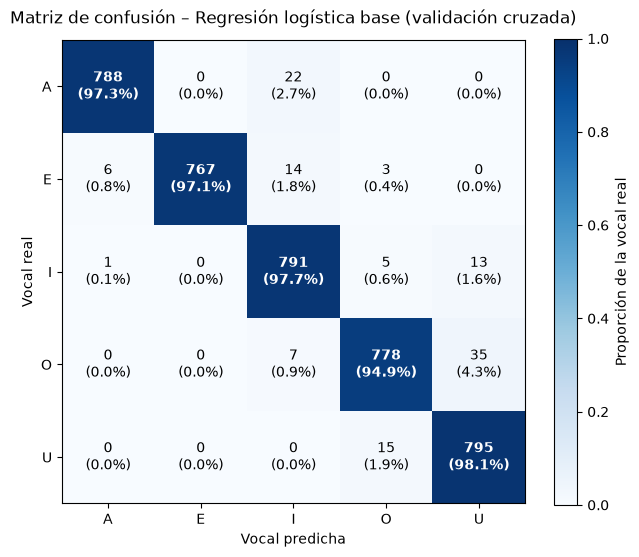


Regresión logística base: métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9912,0.9728,0.9819,810.0,0.9978,0.0022
E,1.0000,0.9709,0.9852,790.0,1.0000,0.0000
I,0.9484,0.9765,0.9623,810.0,0.9867,0.0133
O,0.9713,0.9488,0.9599,820.0,0.9929,0.0071
U,0.9431,0.9815,0.9619,810.0,0.9851,0.0149



Comparación en validación cruzada (media ± desviación)


,accuracy,precision,recall,especificidad,FPR,log_loss
Regresión logística base,0.9700 ± 0.0075,0.9727 ± 0.0062,0.9705 ± 0.0075,0.9925 ± 0.0019,0.0075 ± 0.0019,0.1221 ± 0.0510
Lineal base,0.9577 ± 0.0095,0.9594 ± 0.0087,0.9583 ± 0.0089,0.9894 ± 0.0024,0.0106 ± 0.0024,N/A
Ridge base,0.9580 ± 0.0094,0.9596 ± 0.0086,0.9585 ± 0.0088,0.9895 ± 0.0023,0.0105 ± 0.0023,N/A
Lasso base,0.5809 ± 0.0206,0.4907 ± 0.0360,0.5823 ± 0.0193,0.8951 ± 0.0051,0.1049 ± 0.0051,N/A
Lineal (ajustada),0.8646 ± 0.0108,0.8695 ± 0.0086,0.8650 ± 0.0108,0.9661 ± 0.0027,0.0339 ± 0.0027,N/A
Ridge (ajustado),0.9475 ± 0.0129,0.9506 ± 0.0111,0.9483 ± 0.0124,0.9869 ± 0.0032,0.0131 ± 0.0032,N/A
Lasso (ajustado),0.9565 ± 0.0115,0.9584 ± 0.0104,0.9569 ± 0.0112,0.9891 ± 0.0029,0.0109 ± 0.0029,N/A
Regresión logística (ajustada),0.9742 ± 0.0078,0.9765 ± 0.0067,0.9746 ± 0.0079,0.9936 ± 0.0019,0.0064 ± 0.0019,0.1034 ± 0.0319


In [103]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, make_scorer, classification_report,
                             precision_score, recall_score)
from sklearn.model_selection import (cross_validate, cross_val_predict,
                                     StratifiedGroupKFold)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 20)
warnings.filterwarnings("ignore", category=UserWarning)

# =====================  0. VARIABLES NECESARIAS  =====================
faltan = [n for n in ["X_train", "y_train"] if n not in globals()]
if faltan:
    raise NameError(f"Faltan {faltan}. Ejecuta antes la celda de la sección 11 (partición train/test).")

y_arr = np.asarray(y_train)
CLASES = list(CLASES) if "CLASES" in globals() else sorted(np.unique(y_arr).tolist())

# 'particiones' se crea en la sección 13.6 del notebook; aquí se reconstruye si no existe
if "particiones" not in globals():
    if "g_train" not in globals():
        raise NameError("Falta 'g_train' (grupos por imagen original). "
                        "Ejecuta la celda de la sección 11.1 donde se crea X_train.")
    cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    particiones = list(cv_grupos.split(X_train, y_train, groups=g_train))
particiones = list(particiones)

# Comprobación: cada imagen queda exactamente una vez en validación
val_idx = np.concatenate([v for _, v in particiones])
assert len(val_idx) == len(X_train) and len(set(val_idx)) == len(X_train), \
    "Las particiones no cubren cada imagen exactamente una vez"

# =====================  1. FUNCIONES AUXILIARES  =====================

def especificidad_macro(y_true, y_pred, labels=tuple(CLASES)):
    cm_ = confusion_matrix(y_true, y_pred, labels=list(labels))
    esp_ = []
    for k in range(len(labels)):
        tp = cm_[k, k]
        fp = cm_[:, k].sum() - tp
        fn = cm_[k, :].sum() - tp
        tn = cm_.sum() - tp - fp - fn
        esp_.append(tn / (tn + fp))
    return np.mean(esp_)

SCORING_REG = {
    "accuracy":      "accuracy",
    "precision":     make_scorer(precision_score, average="macro", zero_division=0),
    "recall":        make_scorer(recall_score,    average="macro", zero_division=0),
    "especificidad": make_scorer(especificidad_macro),
}
SCORING_CLF = {**SCORING_REG, "log_loss": "neg_log_loss"}   # modelos con predict_proba


def resumir_cv(cv_res, scoring):
    filas = {}
    for m in scoring:
        for conj, pref in [("validación", "test"), ("entrenamiento", "train")]:
            v = cv_res[f"{pref}_{m}"]
            if m == "log_loss":
                v = -v                                   # sklearn lo devuelve negativo
            filas.setdefault(m, {})[f"{conj} (media)"] = v.mean()
            filas[m][f"{conj} (std)"] = v.std()
    tabla = pd.DataFrame(filas).T
    tabla.loc["FPR"] = [1 - tabla.loc["especificidad", "validación (media)"],
                        tabla.loc["especificidad", "validación (std)"],
                        1 - tabla.loc["especificidad", "entrenamiento (media)"],
                        tabla.loc["especificidad", "entrenamiento (std)"]]
    return tabla.round(4)


def metricas_por_clase(y_real, y_pred, clases):
    cm_ = confusion_matrix(y_real, y_pred, labels=clases)
    rep_ = pd.DataFrame(classification_report(
        y_real, y_pred, labels=clases, output_dict=True, zero_division=0
    )).T.loc[clases, ["precision", "recall", "f1-score", "support"]]
    esp_, fpr_ = [], []
    for k in range(len(clases)):
        tp = cm_[k, k]; fp = cm_[:, k].sum() - tp
        fn = cm_[k, :].sum() - tp; tn = cm_.sum() - tp - fp - fn
        esp_.append(tn / (tn + fp)); fpr_.append(fp / (fp + tn))
    rep_["especificidad"] = esp_
    rep_["FPR"] = fpr_
    return rep_, cm_


def graficar_matriz_confusion(cm_, clases, titulo):
    pct = cm_ / cm_.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(clases)):
        for j in range(len(clases)):
            ax.text(j, i, f"{cm_[i, j]}\n({pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if pct[i, j] > 0.5 else "black", fontsize=10,
                    fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(len(clases))); ax.set_xticklabels(clases)
    ax.set_yticks(range(len(clases))); ax.set_yticklabels(clases)
    ax.set_xlabel("Vocal predicha"); ax.set_ylabel("Vocal real")
    ax.set_title(titulo, fontsize=12, pad=12)
    fig.colorbar(im, ax=ax, label="Proporción de la vocal real")
    plt.tight_layout(); plt.show()


def mostrar(obj):
    try:
        display(obj)
    except NameError:
        print(obj)


def evaluar_modelo(nombre, modelo, X, y, cv, scoring, clases):
    """Validación cruzada + matriz de confusión + métricas por clase."""
    cv_res = cross_validate(modelo, X, y, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-1)
    resumen = resumir_cv(cv_res, scoring)
    y_pred = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)
    rep_, cm_ = metricas_por_clase(y, y_pred, clases)
    print(f"===== {nombre}: métricas (validación cruzada) =====")
    print(resumen)
    graficar_matriz_confusion(cm_, clases, f"Matriz de confusión – {nombre} (validación cruzada)")
    print(f"\n{nombre}: métricas por clase")
    mostrar(rep_.round(4))
    return {"cv": cv_res, "resumen": resumen, "cm": cm_, "rep": rep_, "y_pred": y_pred}


def tabla_comparativa(resultados, metricas=("accuracy", "precision", "recall",
                                            "especificidad", "FPR", "log_loss")):
    filas = {}
    for nombre, r in resultados.items():
        fila = {}
        for m in metricas:
            if m in r["resumen"].index:
                med = r["resumen"].loc[m, "validación (media)"]
                std = r["resumen"].loc[m, "validación (std)"]
                fila[m] = f"{med:.4f} ± {std:.4f}"
            else:
                fila[m] = "N/A"
        filas[nombre] = fila
    return pd.DataFrame(filas).T

# =====================  2. MODELO BASE: REGRESIÓN LOGÍSTICA  =====================

modelo_base = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=42)

res_logistica = evaluar_modelo("Regresión logística base", modelo_base,
                               X_train_PCA, y_train, particiones, SCORING_CLF, CLASES)

# =====================  3. COMPARACIÓN CON LOS DEMÁS MODELOS BASE  =====================

if "resultados" not in globals():
    resultados = {}
resultados["Regresión logística base"] = res_logistica

print("\nComparación en validación cruzada (media ± desviación)")
mostrar(tabla_comparativa(resultados))

Observacion:
El modelo base, se observan buenos resultados este caso la vocal E tiene una buena presicion a comparacion con los demas datos pero aun asi siguen siendo buenos toca tener en cuenta que al momento de utilizar los ajustes ver que cambios tiene
 

In [104]:
import time
from sklearn.linear_model import LogisticRegression

def modelo_logistica(**kw):
    return LogisticRegression(random_state=42, **kw)

def ejecutar_busqueda_clf(nombre, rejilla, X, y, cv, refit="accuracy"):
    t = time.time()
    gs = GridSearchCV(modelo_logistica(max_iter=1000), rejilla, scoring=SCORING_CLF,
                      refit=refit, cv=cv, return_train_score=True, n_jobs=-1)
    gs.fit(X, y)
    print(f"{nombre}: {len(gs.cv_results_['params'])} combinaciones x {len(cv)} folds ({time.time()-t:.0f} s)")
    print("Mejores hiperparámetros:", gs.best_params_)
    print(f"Mejor {refit} de validación (media): {gs.best_score_:.4f}")
    return gs

def resumen_gridsearchCV_clf(gs, metricas=("accuracy", "precision", "recall", "especificidad", "log_loss")):
    r = pd.DataFrame(gs.cv_results_)
    t = pd.DataFrame(list(r["params"]))
    for m in metricas:
        s = -1 if m == "log_loss" else 1          # sklearn guarda el log loss con signo negativo
        t[f"{m} val (media)"] = s * r[f"mean_test_{m}"].values
        t[f"{m} val (std)"]   = r[f"std_test_{m}"].values
        t[f"{m} entren."]     = s * r[f"mean_train_{m}"].values
    t["ranking"] = r[f"rank_test_{gs.refit}"].values
    return t.sort_values("ranking").set_index("ranking").round(4)

def graficar_C(gs, nombre="Regresión logística"):
    r = pd.DataFrame(gs.cv_results_)
    p = pd.DataFrame(list(r["params"]))
    d = pd.concat([p, r.drop(columns="params")], axis=1)
    d = d[d["solver"] == gs.best_params_["solver"]].sort_values("C")
    c_best = gs.best_params_["C"]
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, m, s, tit, ylab in [(ejes[0], "log_loss", -1, "log loss según C (menor es mejor)", "Log loss"),
                                (ejes[1], "accuracy", 1, "accuracy según C (mayor es mejor)", "Accuracy")]:
        ax.plot(d["C"], s * d[f"mean_train_{m}"], marker="s", color="gray", label="Entrenamiento")
        ax.errorbar(d["C"], s * d[f"mean_test_{m}"], yerr=d[f"std_test_{m}"], marker="o", capsize=3,
                    label="Validación (media ± desviación)")
        ax.axvline(c_best, color="red", ls="--", label=f"Mejor C = {c_best}")
        ax.set_xscale("log"); ax.set_xlabel("C (escala logarítmica; menor C = más regularización)")
        ax.set_ylabel(ylab); ax.set_title(f"{nombre}: {tit}"); ax.grid(True, alpha=0.4); ax.legend()
    plt.tight_layout(); plt.show()

Observacion:
Sobreajuste leve. El entrenamiento da accuracy 1,0000 y la validación 0,9725. El log loss pasa de 0,002 a 0,117, con una desviación de 0,05 entre folds, bastante alta respecto a su media. Aunque el modelo acierta casi siempre, en algunos folds queda menos seguro de sus predicciones. Es una buena razón para ajustar en el GridSearchCV

### 13.2 Grafico del modelo base

Vocal A: 810 imágenes reales | no reconocidas: 20 (recall 0.9753) | falsas A: 12


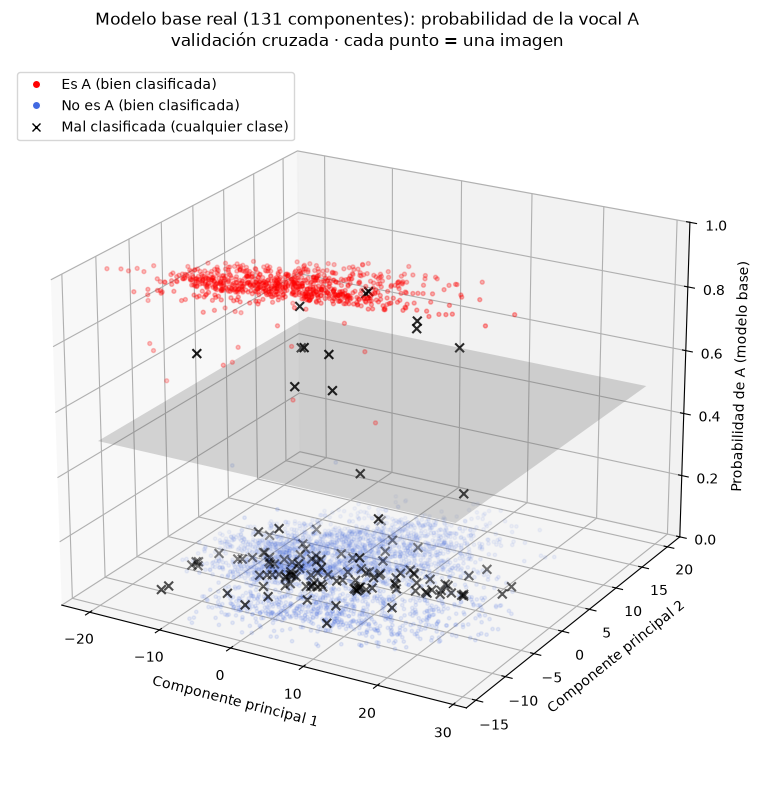

In [105]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.lines import Line2D
from sklearn.model_selection import cross_val_predict
from sklearn.decomposition import PCA

VOCAL = "A"            # cámbiela por A, E, I u O

y_arr = np.asarray(y_train)
clases_ord = sorted(np.unique(y_arr).tolist())      # mismo orden que usa predict_proba
k = clases_ord.index(VOCAL)
particiones = list(particiones)

# Ejes del gráfico: componentes 1 y 2 (solo para ubicar los puntos)
try:
    X2 = np.asarray(X_train_PCA)[:, :2]
except NameError:
    X2 = PCA(n_components=2, random_state=42).fit_transform(X_train)

# Probabilidades REALES del modelo base, de validación cruzada
proba_cv = cross_val_predict(modelo_base, X_train, y_train, cv=particiones,
                             method="predict_proba", n_jobs=-1)
pred_cv = np.array(clases_ord)[proba_cv.argmax(axis=1)]
p = proba_cv[:, k]

es_vocal = y_arr == VOCAL
mal = pred_cv != y_arr                              # error del modelo (argmax)

# --- Consistencia con la matriz de confusión ---
fn = int((es_vocal & (pred_cv != VOCAL)).sum())     # vocales reales que no reconoció
fp = int((~es_vocal & (pred_cv == VOCAL)).sum())    # otras clases que llamó vocal
print(f"Vocal {VOCAL}: {es_vocal.sum()} imágenes reales | "
      f"no reconocidas: {fn} (recall {1 - fn/es_vocal.sum():.4f}) | "
      f"falsas {VOCAL}: {fp}")

# --- Gráfica ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Plano de referencia en p = 0,5
g1 = np.linspace(X2[:, 0].min(), X2[:, 0].max(), 2)
g2 = np.linspace(X2[:, 1].min(), X2[:, 1].max(), 2)
G1, G2 = np.meshgrid(g1, g2)
ax.plot_surface(G1, G2, np.full_like(G1, 0.5), color="gray", alpha=0.25)

ok_n, ok_v = ~es_vocal & ~mal, es_vocal & ~mal
ax.scatter(X2[ok_n, 0], X2[ok_n, 1], p[ok_n], s=6, alpha=0.35, color="royalblue")
ax.scatter(X2[ok_v, 0], X2[ok_v, 1], p[ok_v], s=8, alpha=0.6, color="red")
ax.scatter(X2[mal, 0], X2[mal, 1], p[mal], s=40, marker="x", color="black")

ax.set_xlabel("Componente principal 1")
ax.set_ylabel("Componente principal 2")
ax.set_zlabel(f"Probabilidad de {VOCAL} (modelo base)")
ax.set_zlim(0, 1)
ax.set_title(f"Modelo base real (131 componentes): probabilidad de la vocal {VOCAL}\n"
             "validación cruzada · cada punto = una imagen", pad=14)
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", label=f"Es {VOCAL} (bien clasificada)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="royalblue", label=f"No es {VOCAL} (bien clasificada)"),
    Line2D([0], [0], marker="x", color="black", linestyle="", label="Mal clasificada (cualquier clase)"),
], loc="upper left")
ax.view_init(elev=22, azim=-60)
plt.tight_layout()
plt.show()

Esto es una ilustración, no es modelo real. el modelo base usa 131 variables y predice 5 salidas a la vez, lo que equivale a un “hiperplano” en 131 dimensiones y teniendo en cuenta que no puede dibujar. Para poder mostrar un plano se reduce a 2 variables y 1 vocal. Para cambiar la vocal que se encuentra en la imagen toca cambiar la vocal al inicio de la implementacion del grafico

### Lineal 

===== Lineal base: métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.9577            0.0095                 0.9884               0.0016
precision                  0.9594            0.0087                 0.9886               0.0015
recall                     0.9583            0.0089                 0.9885               0.0015
especificidad              0.9894            0.0024                 0.9971               0.0004
FPR                        0.0106            0.0024                 0.0029               0.0004


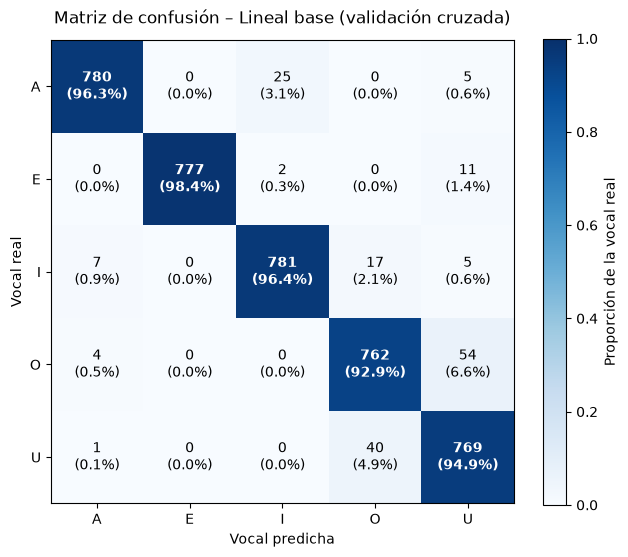


Lineal base: métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9848,0.9630,0.9738,810.0,0.9963,0.0037
E,1.0000,0.9835,0.9917,790.0,1.0000,0.0000
I,0.9666,0.9642,0.9654,810.0,0.9916,0.0084
O,0.9304,0.9293,0.9298,820.0,0.9823,0.0177
U,0.9111,0.9494,0.9299,810.0,0.9768,0.0232


In [106]:
lineal_base = RegresionLinealClasificador(modelo="lineal")

res_lineal = evaluar_modelo("Lineal base", lineal_base, X_train_PCA, y_train, particiones, SCORING_REG, CLASES)
resultados["Lineal base"] = res_lineal

Observacion:
El resultado es el esperado. alpha no existe en la regresión lineal sin penalización. La clase RegresionLinealClasificador lo recibe, pero cuando modelo="lineal" crea un LinearRegression() sin usarlo. Por eso cambiarlo de 1 a 100, a 1000 o a lo que sea no altera nada en ese modelo.

### Ridge base

===== Ridge base: métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.9580            0.0094                 0.9884               0.0015
precision                  0.9596            0.0086                 0.9885               0.0015
recall                     0.9585            0.0088                 0.9884               0.0015
especificidad              0.9895            0.0023                 0.9971               0.0004
FPR                        0.0105            0.0023                 0.0029               0.0004


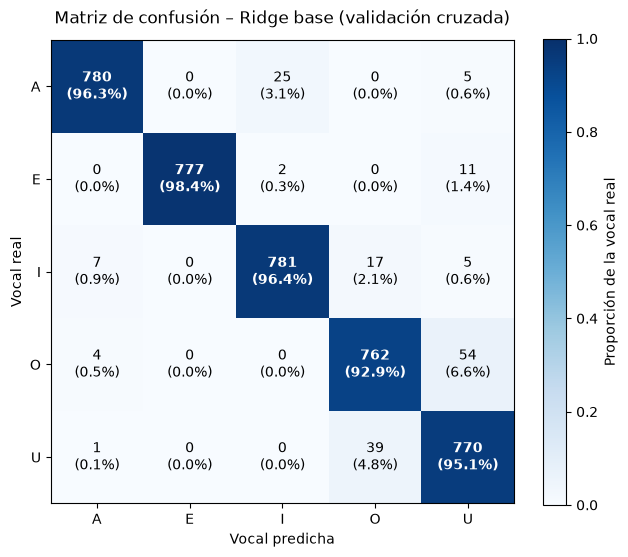


Ridge base: métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9848,0.9630,0.9738,810.0,0.9963,0.0037
E,1.0000,0.9835,0.9917,790.0,1.0000,0.0000
I,0.9666,0.9642,0.9654,810.0,0.9916,0.0084
O,0.9315,0.9293,0.9304,820.0,0.9826,0.0174
U,0.9112,0.9506,0.9305,810.0,0.9768,0.0232


In [107]:
ridge_base = RegresionLinealClasificador(modelo="ridge", alpha=1.0)

res_ridge = evaluar_modelo("Ridge base", ridge_base, X_train_PCA, y_train, particiones, SCORING_REG, CLASES)
resultados["Ridge base"] = res_ridge

Con alpha = 1, Ridge obtuvo prácticamente los mismos resultados que la regresión lineal: accuracy de prueba de 0,9369 en ambos.

### Lasso base

===== Lasso base: métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.5809            0.0206                 0.5811               0.0060
precision                  0.4907            0.0360                 0.4897               0.0081
recall                     0.5823            0.0193                 0.5824               0.0050
especificidad              0.8951            0.0051                 0.8952               0.0015
FPR                        0.1049            0.0051                 0.1048               0.0015


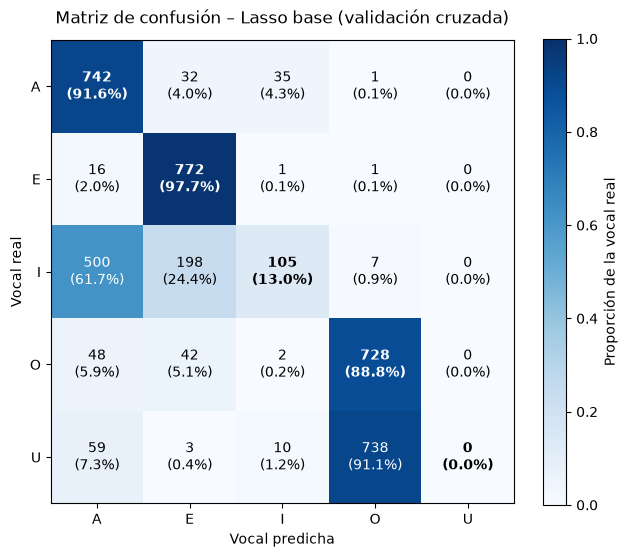


Lasso base: métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.5436,0.9160,0.6823,810.0,0.8071,0.1929
E,0.7373,0.9772,0.8405,790.0,0.9154,0.0846
I,0.6863,0.1296,0.2181,810.0,0.9851,0.0149
O,0.4936,0.8878,0.6344,820.0,0.7680,0.2320
U,0.0000,0.0000,0.0000,810.0,1.0000,0.0000


In [108]:
lasso_base = RegresionLinealClasificador(modelo="lasso", alpha=1.0)

res_lasso = evaluar_modelo("Lasso base", lasso_base, X_train_PCA, y_train, particiones, SCORING_REG, CLASES)
resultados["Lasso base"] = res_lasso

Observacion:
Lasso presenta una gran irregularidad entre los resultados obtenidos. se hace un sobre ajuste alto para ver los resultados obtenidos y poderlos comparar. otro punto es revisar porque en las metricas base nos dio 0

#### Comparación de los modelos base y coeficientes

In [109]:
print("Comparación en validación cruzada (media ± desviación)")
mostrar(tabla_comparativa(resultados))

# Coeficientes (ajuste con todo el entrenamiento; no se usa el conjunto de prueba)
lineal_base.fit(X_train_PCA, y_train)
ridge_base.fit(X_train_PCA, y_train)
lasso_base.fit(X_train_PCA, y_train)
print("\nCoeficientes de los modelos base")
mostrar(resumen_coeficientes([("Lineal base", lineal_base), ("Ridge base", ridge_base), ("Lasso base", lasso_base)]))

Comparación en validación cruzada (media ± desviación)


,accuracy,precision,recall,especificidad,FPR,log_loss
Regresión logística base,0.9700 ± 0.0075,0.9727 ± 0.0062,0.9705 ± 0.0075,0.9925 ± 0.0019,0.0075 ± 0.0019,0.1221 ± 0.0510
Lineal base,0.9577 ± 0.0095,0.9594 ± 0.0087,0.9583 ± 0.0089,0.9894 ± 0.0024,0.0106 ± 0.0024,N/A
Ridge base,0.9580 ± 0.0094,0.9596 ± 0.0086,0.9585 ± 0.0088,0.9895 ± 0.0023,0.0105 ± 0.0023,N/A
Lasso base,0.5809 ± 0.0206,0.4907 ± 0.0360,0.5823 ± 0.0193,0.8951 ± 0.0051,0.1049 ± 0.0051,N/A
Lineal (ajustada),0.8646 ± 0.0108,0.8695 ± 0.0086,0.8650 ± 0.0108,0.9661 ± 0.0027,0.0339 ± 0.0027,N/A
Ridge (ajustado),0.9475 ± 0.0129,0.9506 ± 0.0111,0.9483 ± 0.0124,0.9869 ± 0.0032,0.0131 ± 0.0032,N/A
Lasso (ajustado),0.9565 ± 0.0115,0.9584 ± 0.0104,0.9569 ± 0.0112,0.9891 ± 0.0029,0.0109 ± 0.0029,N/A
Regresión logística (ajustada),0.9742 ± 0.0078,0.9765 ± 0.0067,0.9746 ± 0.0079,0.9936 ± 0.0019,0.0064 ± 0.0019,0.1034 ± 0.0319



Coeficientes de los modelos base


,Coeficientes totales,Distintos de cero,Iguales a cero,Promedio de |coef|
Modelo,,,,
Lineal base,655,655,0,0.01793
Ridge base,655,655,0,0.01792
Lasso base,655,6,649,0.00007


In [110]:
def _onehot(y):
    return (np.asarray(y)[:, None] == np.asarray(CLASES)[None, :]).astype(float)

def _scorer_onehot(f, signo=1):
    def scorer(estimador, X, y):
        return signo * f(_onehot(y), estimador.decision_function(X))
    return scorer

_mse  = lambda Y, P: mean_squared_error(Y, P)
_rmse = lambda Y, P: np.sqrt(mean_squared_error(Y, P))
_mae  = lambda Y, P: mean_absolute_error(Y, P)
_r2   = lambda Y, P: r2_score(Y, P)

SCORING_REG_EXT = {**SCORING_REG,
                   "MSE": _scorer_onehot(_mse), "RMSE": _scorer_onehot(_rmse),
                   "MAE": _scorer_onehot(_mae)}
#SCORING_GS = {**SCORING_REG_EXT, "neg_RMSE": _scorer_onehot(_rmse, signo=-1)}

In [111]:
class RegresionLinealClasificador(ClassifierMixin, BaseEstimator):
    """Regresión lineal / Ridge / Lasso sobre etiquetas one-hot; predice la clase de mayor salida."""
    def __init__(self, modelo="ridge", alpha=1.0, max_iter=10000, fit_intercept=True, positive=False):
        self.modelo = modelo
        self.alpha = alpha
        self.max_iter = max_iter
        self.fit_intercept = fit_intercept
        self.positive = positive

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        Y = (y[:, None] == self.classes_[None, :]).astype(float)
        if self.modelo == "lineal":
            self.reg_ = LinearRegression(fit_intercept=self.fit_intercept, positive=self.positive)
        elif self.modelo == "ridge":
            self.reg_ = Ridge(alpha=self.alpha, fit_intercept=self.fit_intercept)
        elif self.modelo == "lasso":
            self.reg_ = Lasso(alpha=self.alpha, max_iter=self.max_iter, fit_intercept=self.fit_intercept)
        else:
            raise ValueError(f"modelo desconocido: {self.modelo!r} (use 'lineal', 'ridge' o 'lasso')")
        self.reg_.fit(X, Y)
        return self

    def decision_function(self, X):
        return self.reg_.predict(X)

    def predict(self, X):
        return self.classes_[self.decision_function(X).argmax(axis=1)]

### Funciones de búsqueda

In [112]:
import time
import inspect

def ejecutar_busqueda(nombre, modelo, rejilla, X, y, cv, refit="accuracy"):
    t = time.time()
    gs = GridSearchCV(RegresionLinealClasificador(modelo=modelo), rejilla, scoring=SCORING_REG_EXT, refit=refit,
                      cv=cv, return_train_score=True, n_jobs=-1)
    gs.fit(X, y)
    print(f"{nombre}: {len(gs.cv_results_['params'])} combinaciones x {len(cv)} folds ({time.time()-t:.0f} s)")
    print("Mejores hiperparámetros:", gs.best_params_)
    print(f"Mejor {refit} de validación (media): {gs.best_score_:.4f}")
    return gs

def resumen_gridsearch(gs, metricas=("accuracy", "precision", "recall", "especificidad",
                                     "MSE", "RMSE", "MAE")):
    r = pd.DataFrame(gs.cv_results_)
    t = pd.DataFrame(list(r["params"]))
    for m in metricas:
        t[f"{m} val (media)"] = r[f"mean_test_{m}"].values
        t[f"{m} val (std)"]   = r[f"std_test_{m}"].values
        t[f"{m} entren."]     = r[f"mean_train_{m}"].values
    t["ranking"] = r[f"rank_test_{gs.refit}"].values
    return t.sort_values("ranking").set_index("ranking").round(4)

def graficar_alpha(gs, nombre):
    r = pd.DataFrame(gs.cv_results_)
    p = pd.DataFrame(list(r["params"]))
    d = pd.concat([p, r.drop(columns="params")], axis=1)
    d = d[d["fit_intercept"] == gs.best_params_["fit_intercept"]].sort_values("alpha")
    a_best = gs.best_params_["alpha"]
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, m, tit, ylab in [(ejes[0], "RMSE", "RMSE según alpha (menor es mejor)", "RMSE"),
                             (ejes[1], "accuracy", "accuracy según alpha (mayor es mejor)", "Accuracy")]:
        ax.plot(d["alpha"], d[f"mean_train_{m}"], marker="s", color="gray", label="Entrenamiento")
        ax.errorbar(d["alpha"], d[f"mean_test_{m}"], yerr=d[f"std_test_{m}"], marker="o", capsize=3,
                    label="Validación (media ± desviación)")
        ax.axvline(a_best, color="red", ls="--", label=f"Mejor alpha = {a_best}")
        ax.set_xscale("log"); ax.set_xlabel("alpha (escala logarítmica)"); ax.set_ylabel(ylab)
        ax.set_title(f"{nombre}: {tit}"); ax.grid(True, alpha=0.4); ax.legend()
    plt.tight_layout(); plt.show()


def graficar_lineal(gs, nombre="Regresión lineal"):
    r = pd.DataFrame(gs.cv_results_)
    etiquetas = [f"intercepto={p['fit_intercept']}\npositive={p['positive']}" for p in r["params"]]
    mejor = gs.best_index_
    x = np.arange(len(r)); w = 0.38
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, m, tit, ylab in [(ejes[0], "RMSE", "RMSE por combinación (menor es mejor)", "RMSE"),
                             (ejes[1], "accuracy", "accuracy por combinación (mayor es mejor)", "Accuracy")]:
        ax.bar(x - w/2, r[f"mean_train_{m}"], w, color="gray", label="Entrenamiento")
        ax.bar(x + w/2, r[f"mean_test_{m}"], w, yerr=r[f"std_test_{m}"], capsize=4,
               color="tab:blue", label="Validación (media ± desviación)")
        ax.set_xticks(x); ax.set_xticklabels(etiquetas)
        ax.get_xticklabels()[mejor].set_fontweight("bold")
        ax.set_ylabel(ylab); ax.set_title(f"{nombre}: {tit}")
        ax.grid(True, axis="y", alpha=0.4); ax.legend()
    plt.tight_layout(); plt.show()

### 13.4 Evaluación final

### Regresión lineal

Regresión lineal: 2 combinaciones x 5 folds (0 s)
Mejores hiperparámetros: {'fit_intercept': True, 'positive': False}
Mejor accuracy de validación (media): 0.9577


,fit_intercept,positive,accuracy val (media),accuracy val (std),accuracy entren.,precision val (media),precision val (std),precision entren.,recall val (media),recall val (std),...,especificidad entren.,MSE val (media),MSE val (std),MSE entren.,RMSE val (media),RMSE val (std),RMSE entren.,MAE val (media),MAE val (std),MAE entren.
ranking,,,,,,,,,,,,,,,,,,,,,
1,True,False,0.9577,0.0095,0.9884,0.9594,0.0087,0.9886,0.9583,0.0089,...,0.9971,0.0406,0.0058,0.0252,0.201,0.0146,0.1588,0.1443,0.0072,0.1172
2,True,True,0.8823,0.0278,0.9644,0.8859,0.0279,0.9649,0.8828,0.0275,...,0.9911,0.1064,0.0065,0.0870,0.326,0.0101,0.2950,0.2497,0.0093,0.2270


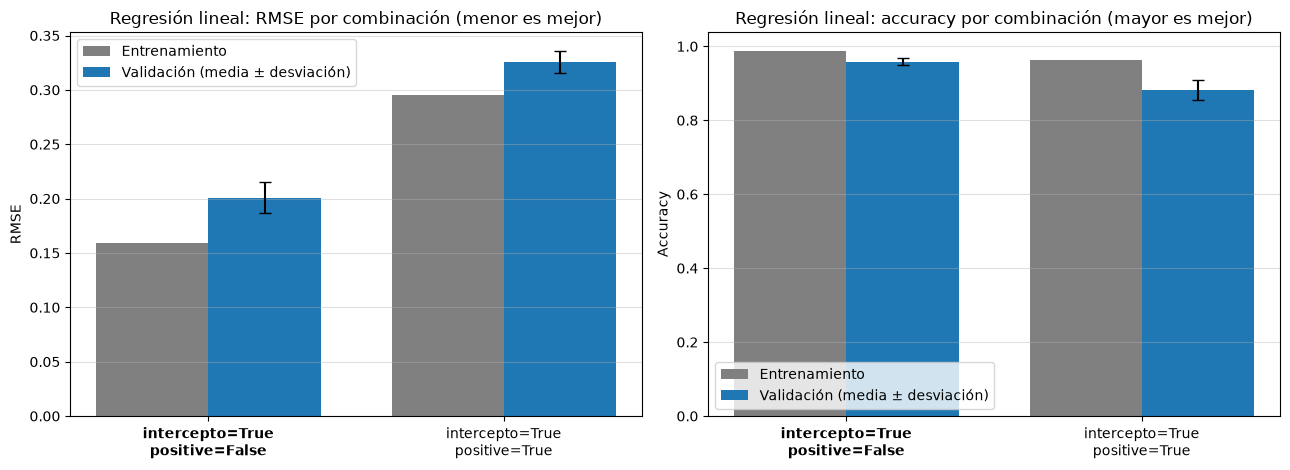

In [113]:
gs_lineal = ejecutar_busqueda("Regresión lineal", "lineal",
                              {"fit_intercept": [True], "positive": [False, True]},
                              X_train_PCA, y_train, particiones)
mostrar(resumen_gridsearch(gs_lineal))
graficar_lineal(gs_lineal, "Regresión lineal")

### Ridge

Ridge: 9 combinaciones x 5 folds (1 s)
Mejores hiperparámetros: {'alpha': 5, 'fit_intercept': True}
Mejor accuracy de validación (media): 0.9580


,alpha,fit_intercept,accuracy val (media),accuracy val (std),accuracy entren.,precision val (media),precision val (std),precision entren.,recall val (media),recall val (std),...,especificidad entren.,MSE val (media),MSE val (std),MSE entren.,RMSE val (media),RMSE val (std),RMSE entren.,MAE val (media),MAE val (std),MAE entren.
ranking,,,,,,,,,,,,,,,,,,,,,
1,5.0000,True,0.9580,0.0099,0.9883,0.9597,0.0091,0.9884,0.9585,0.0094,...,0.9971,0.0405,0.0057,0.0252,0.2006,0.0144,0.1588,0.1441,0.0071,0.1172
1,10.0000,True,0.9580,0.0099,0.9882,0.9597,0.0091,0.9883,0.9585,0.0094,...,0.9970,0.0403,0.0057,0.0252,0.2003,0.0143,0.1588,0.1439,0.0071,0.1172
3,1.0000,True,0.9580,0.0094,0.9884,0.9596,0.0086,0.9885,0.9585,0.0088,...,0.9971,0.0406,0.0058,0.0252,0.2009,0.0145,0.1588,0.1442,0.0072,0.1172
4,0.0001,True,0.9577,0.0095,0.9884,0.9594,0.0087,0.9886,0.9583,0.0089,...,0.9971,0.0406,0.0058,0.0252,0.2010,0.0146,0.1588,0.1443,0.0072,0.1172
4,0.0500,True,0.9577,0.0095,0.9884,0.9594,0.0087,0.9886,0.9583,0.0089,...,0.9971,0.0406,0.0058,0.0252,0.2010,0.0146,0.1588,0.1443,0.0072,0.1172
4,0.0100,True,0.9577,0.0095,0.9884,0.9594,0.0087,0.9886,0.9583,0.0089,...,0.9971,0.0406,0.0058,0.0252,0.2010,0.0146,0.1588,0.1443,0.0072,0.1172
4,0.5000,True,0.9577,0.0095,0.9884,0.9594,0.0087,0.9886,0.9583,0.0089,...,0.9971,0.0406,0.0058,0.0252,0.2009,0.0146,0.1588,0.1442,0.0072,0.1172
4,0.0010,True,0.9577,0.0095,0.9884,0.9594,0.0087,0.9886,0.9583,0.0089,...,0.9971,0.0406,0.0058,0.0252,0.2010,0.0146,0.1588,0.1443,0.0072,0.1172


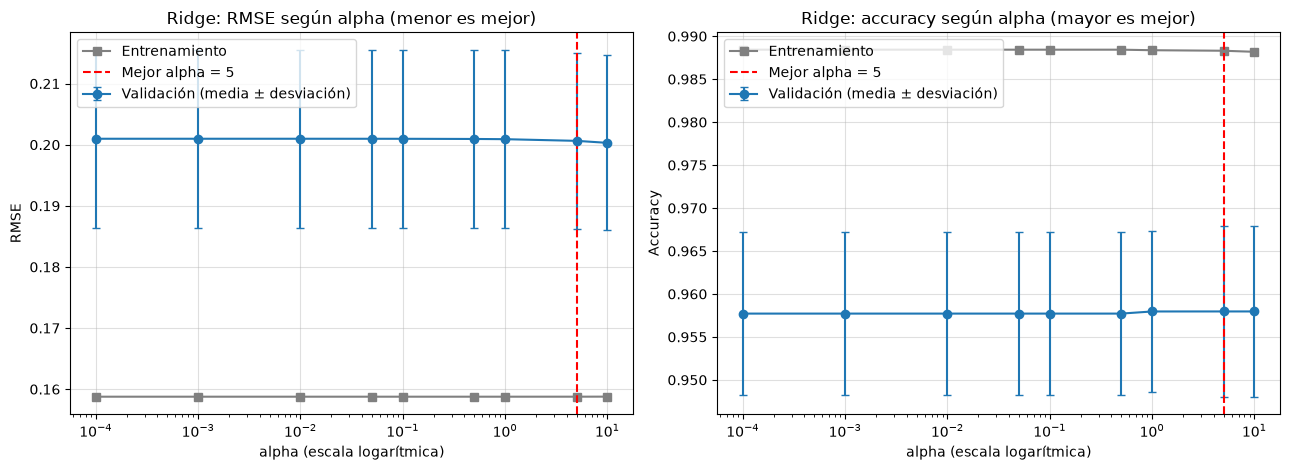

In [114]:
gs_ridge = ejecutar_busqueda("Ridge", "ridge",
                             {"alpha": [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                              "fit_intercept": [True]},
                             X_train_PCA, y_train, particiones)
mostrar(resumen_gridsearch(gs_ridge).head(8))
graficar_alpha(gs_ridge, "Ridge")

### Lasso

Lasso: 9 combinaciones x 5 folds (1 s)
Mejores hiperparámetros: {'alpha': 0.001, 'fit_intercept': True}
Mejor accuracy de validación (media): 0.9592


,alpha,fit_intercept,accuracy val (media),accuracy val (std),accuracy entren.,precision val (media),precision val (std),precision entren.,recall val (media),recall val (std),...,especificidad entren.,MSE val (media),MSE val (std),MSE entren.,RMSE val (media),RMSE val (std),RMSE entren.,MAE val (media),MAE val (std),MAE entren.
ranking,,,,,,,,,,,,,,,,,,,,,
1,0.0010,True,0.9592,0.0096,0.9869,0.9609,0.0089,0.9871,0.9596,0.0095,...,0.9967,0.0386,0.0049,0.0257,0.1960,0.0126,0.1602,0.1415,0.0068,0.1182
2,0.0001,True,0.9580,0.0099,0.9883,0.9597,0.0091,0.9884,0.9585,0.0094,...,0.9971,0.0403,0.0057,0.0252,0.2003,0.0143,0.1588,0.1438,0.0071,0.1172
3,0.0100,True,0.9495,0.0130,0.9726,0.9520,0.0121,0.9731,0.9499,0.0126,...,0.9931,0.0420,0.0034,0.0359,0.2047,0.0083,0.1895,0.1520,0.0064,0.1418
4,0.0500,True,0.9245,0.0177,0.9392,0.9275,0.0189,0.9401,0.9250,0.0167,...,0.9848,0.0553,0.0021,0.0524,0.2351,0.0045,0.2288,0.1792,0.0031,0.1745
5,0.1000,True,0.8986,0.0222,0.9090,0.9009,0.0245,0.9103,0.8995,0.0210,...,0.9772,0.0701,0.0010,0.0676,0.2647,0.0020,0.2600,0.2019,0.0017,0.1982
6,0.5000,True,0.6592,0.0171,0.6641,0.6566,0.0202,0.6585,0.6618,0.0180,...,0.9160,0.1120,0.0021,0.1114,0.3347,0.0031,0.3338,0.2574,0.0020,0.2567
7,1.0000,True,0.5809,0.0206,0.5811,0.4907,0.0360,0.4897,0.5823,0.0193,...,0.8952,0.1379,0.0006,0.1376,0.3714,0.0008,0.3710,0.2941,0.0011,0.2938
8,5.0000,True,0.1980,0.0010,0.2030,0.0396,0.0002,0.0406,0.2000,0.0000,...,0.8000,0.1600,0.0000,0.1600,0.4000,0.0000,0.4000,0.3200,0.0000,0.3200


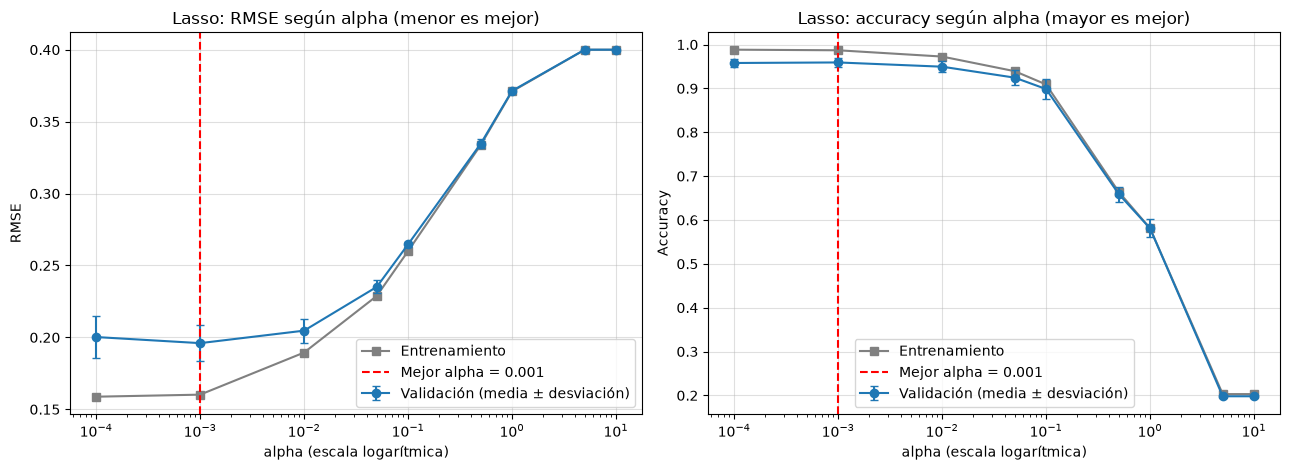

In [115]:
gs_lasso = ejecutar_busqueda("Lasso", "lasso",
                             {"alpha": [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                              "fit_intercept": [True]},
                             X_train_PCA, y_train, particiones)
mostrar(resumen_gridsearch(gs_lasso).head(8))
graficar_alpha(gs_lasso, "Lasso")

### logística

Regresión logística: 18 combinaciones x 5 folds (3 s)
Mejores hiperparámetros: {'C': 0.05, 'solver': 'newton-cg'}
Mejor accuracy de validación (media): 0.9735


,C,solver,accuracy val (media),accuracy val (std),accuracy entren.,precision val (media),precision val (std),precision entren.,recall val (media),recall val (std),recall entren.,especificidad val (media),especificidad val (std),especificidad entren.,log_loss val (media),log_loss val (std),log_loss entren.
ranking,,,,,,,,,,,,,,,,,
1,0.05,newton-cg,0.9735,0.0082,0.9996,0.9759,0.0070,0.9996,0.9738,0.0083,0.9996,0.9934,0.0021,0.9999,0.1035,0.0323,0.0199
2,0.05,lbfgs,0.9733,0.0084,0.9996,0.9757,0.0072,0.9996,0.9736,0.0085,0.9996,0.9933,0.0021,0.9999,0.1033,0.0323,0.0199
2,0.10,newton-cg,0.9733,0.0084,0.9999,0.9757,0.0072,0.9999,0.9736,0.0085,0.9999,0.9933,0.0021,1.0000,0.1030,0.0362,0.0122
2,0.10,lbfgs,0.9733,0.0084,0.9999,0.9757,0.0072,0.9999,0.9736,0.0085,0.9999,0.9933,0.0021,1.0000,0.1028,0.0364,0.0122
5,0.01,newton-cg,0.9718,0.0106,0.9975,0.9742,0.0094,0.9976,0.9720,0.0105,0.9975,0.9929,0.0026,0.9994,0.1251,0.0237,0.0571
6,0.50,newton-cg,0.9715,0.0064,1.0000,0.9740,0.0053,1.0000,0.9719,0.0065,1.0000,0.9929,0.0016,1.0000,0.1130,0.0451,0.0037
7,0.01,lbfgs,0.9715,0.0099,0.9975,0.9739,0.0089,0.9976,0.9718,0.0099,0.9975,0.9929,0.0025,0.9994,0.1250,0.0237,0.0571
8,0.50,lbfgs,0.9713,0.0069,1.0000,0.9738,0.0056,1.0000,0.9717,0.0069,1.0000,0.9928,0.0017,1.0000,0.1134,0.0467,0.0037


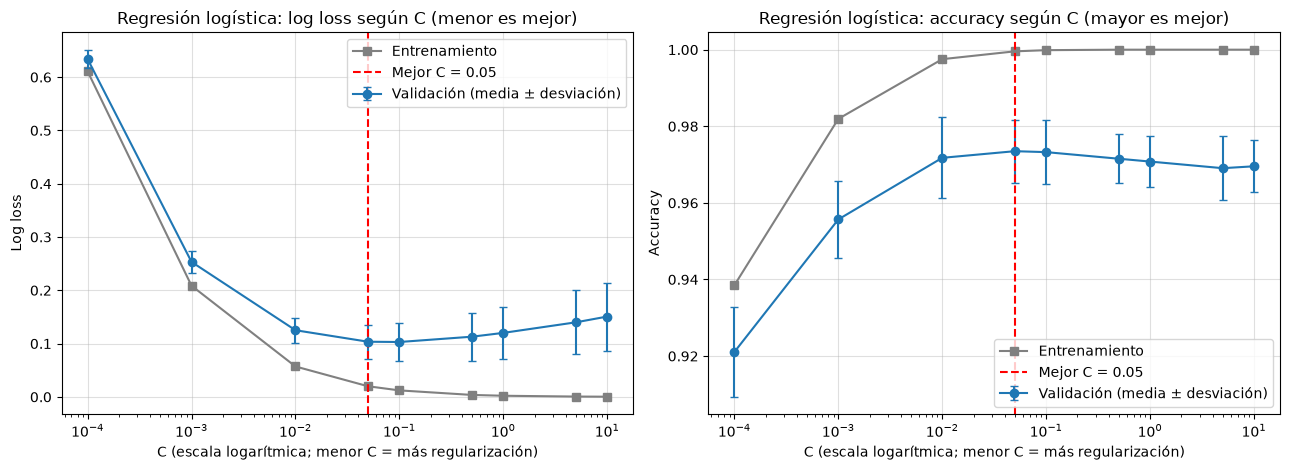

Iteraciones del mejor modelo: 10


In [116]:
rejilla_log = {"C": [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1, 5, 10],
               "solver": ["lbfgs", "newton-cg"]}

gs_log = ejecutar_busqueda_clf("Regresión logística", rejilla_log, X_train_PCA, y_train, particiones)
mostrar(resumen_gridsearchCV_clf(gs_log).head(8))
graficar_C(gs_log)

# Comprobación de convergencia: las iteraciones usadas deben ser menores que max_iter (1000)
print("Iteraciones del mejor modelo:", int(np.max(gs_log.best_estimator_.n_iter_)))

### Mejores modelos y comparación final de la sección

===== Lineal (ajustada): métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.8646            0.0108                    1.0                  0.0
precision                  0.8695            0.0086                    1.0                  0.0
recall                     0.8650            0.0108                    1.0                  0.0
especificidad              0.9661            0.0027                    1.0                  0.0
MSE                        0.1345            0.0184                    0.0                  0.0
RMSE                       0.3660            0.0248                    0.0                  0.0
MAE                        0.2575            0.0125                    0.0                  0.0
FPR                        0.0339            0.0027                    0.0                  0.0


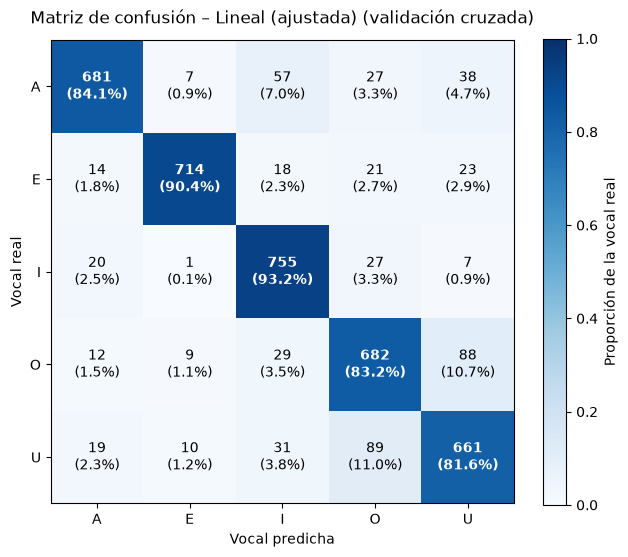


Lineal (ajustada): métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9129,0.8407,0.8753,810.0,0.9799,0.0201
E,0.9636,0.9038,0.9327,790.0,0.9917,0.0083
I,0.8483,0.9321,0.8882,810.0,0.9582,0.0418
O,0.8061,0.8317,0.8187,820.0,0.9491,0.0509
U,0.8091,0.8160,0.8125,810.0,0.9517,0.0483


In [117]:
res_lineal_gs = evaluar_modelo("Lineal (ajustada)", gs_lineal.best_estimator_, X_train, y_train, particiones, SCORING_REG_EXT, CLASES)

### 13.3 Ajuste de hiperparámetros con GridSearchCV

Observacion:
los resultados se mantuvieron iguales no hubo cambios

===== Ridge (ajustado): métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.9475            0.0129                 1.0000               0.0000
precision                  0.9506            0.0111                 1.0000               0.0000
recall                     0.9483            0.0124                 1.0000               0.0000
especificidad              0.9869            0.0032                 1.0000               0.0000
MSE                        0.0504            0.0088                 0.0056               0.0002
RMSE                       0.2238            0.0190                 0.0746               0.0012
MAE                        0.1532            0.0069                 0.0539               0.0009
FPR                        0.0131            0.0032                 0.0000               0.0000


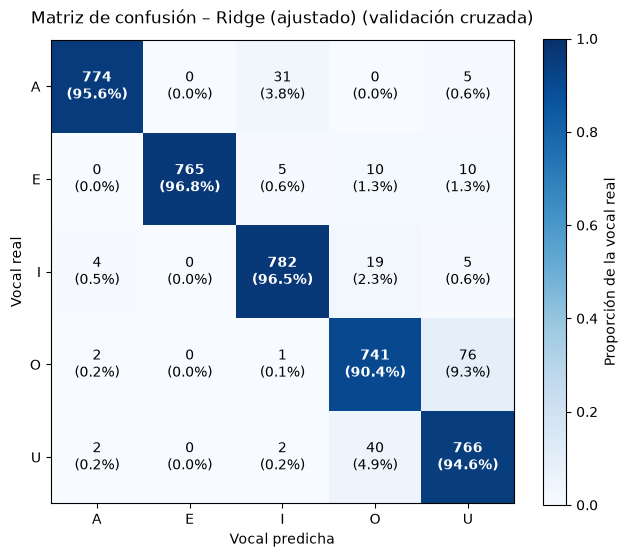


Ridge (ajustado): métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9898,0.9556,0.9724,810.0,0.9975,0.0025
E,1.0000,0.9684,0.9839,790.0,1.0000,0.0000
I,0.9525,0.9654,0.9589,810.0,0.9879,0.0121
O,0.9148,0.9037,0.9092,820.0,0.9786,0.0214
U,0.8886,0.9457,0.9163,810.0,0.9703,0.0297


In [118]:
res_ridge_gs  = evaluar_modelo("Ridge (ajustado)",  gs_ridge.best_estimator_,  X_train, y_train, particiones, SCORING_REG_EXT, CLASES)

Observacion:
se noto un pequeño cambio en la U disminiyo 0.2 del resto se mantuvo igual  

===== Lasso (ajustado): métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.9565            0.0115                 0.9877               0.0014
precision                  0.9584            0.0104                 0.9878               0.0014
recall                     0.9569            0.0112                 0.9877               0.0014
especificidad              0.9891            0.0029                 0.9969               0.0004
MSE                        0.0365            0.0037                 0.0238               0.0006
RMSE                       0.1907            0.0097                 0.1541               0.0019
MAE                        0.1364            0.0063                 0.1119               0.0016
FPR                        0.0109            0.0029                 0.0031               0.0004


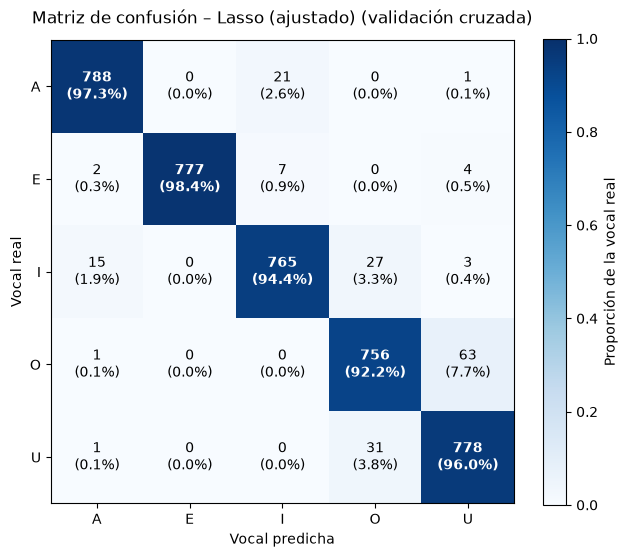


Lasso (ajustado): métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9765,0.9728,0.9746,810.0,0.9941,0.0059
E,1.0000,0.9835,0.9917,790.0,1.0000,0.0000
I,0.9647,0.9444,0.9545,810.0,0.9913,0.0087
O,0.9287,0.9220,0.9253,820.0,0.9820,0.0180
U,0.9164,0.9605,0.9379,810.0,0.9780,0.0220


In [119]:
res_lasso_gs  = evaluar_modelo("Lasso (ajustado)",  gs_lasso.best_estimator_,  X_train, y_train, particiones, SCORING_REG_EXT, CLASES)

Observacion:
Uno una gran diferencia al momento de ajustar con GridSearchCV 

===== Regresión logística (ajustada): métricas (validación cruzada) =====
               validación (media)  validación (std)  entrenamiento (media)  entrenamiento (std)
accuracy                   0.9742            0.0078                 1.0000               0.0000
precision                  0.9765            0.0067                 1.0000               0.0000
recall                     0.9746            0.0079                 1.0000               0.0000
especificidad              0.9936            0.0019                 1.0000               0.0000
log_loss                   0.1034            0.0319                 0.0182               0.0007
FPR                        0.0064            0.0019                 0.0000               0.0000


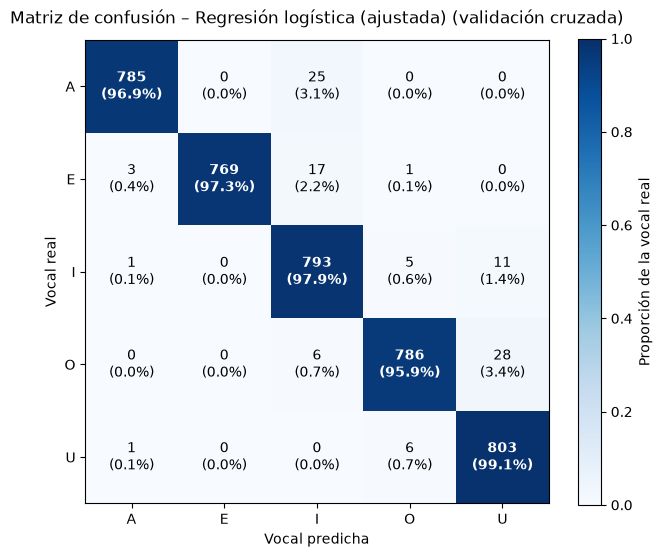


Regresión logística (ajustada): métricas por clase


,precision,recall,f1-score,support,especificidad,FPR
A,0.9937,0.9691,0.9812,810.0,0.9985,0.0015
E,1.0000,0.9734,0.9865,790.0,1.0000,0.0000
I,0.9429,0.9790,0.9606,810.0,0.9851,0.0149
O,0.9850,0.9585,0.9716,820.0,0.9963,0.0037
U,0.9537,0.9914,0.9722,810.0,0.9879,0.0121


In [120]:
res_log_gs = evaluar_modelo("Regresión logística (ajustada)", gs_log.best_estimator_,X_train, y_train, particiones, SCORING_CLF, CLASES)

In [121]:
resultados.update({"Lineal (ajustada)": res_lineal_gs, "Ridge (ajustado)": res_ridge_gs, "Lasso (ajustado)": res_lasso_gs, "Regresión logística (ajustada)" : res_log_gs})
mostrar(tabla_comparativa(resultados, metricas=("accuracy", "precision", "recall", "especificidad",
                                                "FPR", "MSE", "RMSE", "MAE", "log_loss")))

,accuracy,precision,recall,especificidad,FPR,MSE,RMSE,MAE,log_loss
Regresión logística base,0.9700 ± 0.0075,0.9727 ± 0.0062,0.9705 ± 0.0075,0.9925 ± 0.0019,0.0075 ± 0.0019,N/A,N/A,N/A,0.1221 ± 0.0510
Lineal base,0.9577 ± 0.0095,0.9594 ± 0.0087,0.9583 ± 0.0089,0.9894 ± 0.0024,0.0106 ± 0.0024,N/A,N/A,N/A,N/A
Ridge base,0.9580 ± 0.0094,0.9596 ± 0.0086,0.9585 ± 0.0088,0.9895 ± 0.0023,0.0105 ± 0.0023,N/A,N/A,N/A,N/A
Lasso base,0.5809 ± 0.0206,0.4907 ± 0.0360,0.5823 ± 0.0193,0.8951 ± 0.0051,0.1049 ± 0.0051,N/A,N/A,N/A,N/A
Lineal (ajustada),0.8646 ± 0.0108,0.8695 ± 0.0086,0.8650 ± 0.0108,0.9661 ± 0.0027,0.0339 ± 0.0027,0.1345 ± 0.0184,0.3660 ± 0.0248,0.2575 ± 0.0125,N/A
Ridge (ajustado),0.9475 ± 0.0129,0.9506 ± 0.0111,0.9483 ± 0.0124,0.9869 ± 0.0032,0.0131 ± 0.0032,0.0504 ± 0.0088,0.2238 ± 0.0190,0.1532 ± 0.0069,N/A
Lasso (ajustado),0.9565 ± 0.0115,0.9584 ± 0.0104,0.9569 ± 0.0112,0.9891 ± 0.0029,0.0109 ± 0.0029,0.0365 ± 0.0037,0.1907 ± 0.0097,0.1364 ± 0.0063,N/A
Regresión logística (ajustada),0.9742 ± 0.0078,0.9765 ± 0.0067,0.9746 ± 0.0079,0.9936 ± 0.0019,0.0064 ± 0.0019,N/A,N/A,N/A,0.1034 ± 0.0319


In [122]:

print("\nCoeficientes de los modelos ajustados")
mostrar(resumen_coeficientes([("Lineal (ajustada)", gs_lineal.best_estimator_),
                              ("Ridge (ajustado)", gs_ridge.best_estimator_),
                              ("Lasso (ajustado)", gs_lasso.best_estimator_),
                              ("Regresión logística (ajustada)", gs_log.best_estimator_)]))


Coeficientes de los modelos ajustados


,Coeficientes totales,Distintos de cero,Iguales a cero,Promedio de |coef|
Modelo,,,,
Lineal (ajustada),655,655,0,0.01793
Ridge (ajustado),655,655,0,0.01785
Lasso (ajustado),655,567,88,0.01454
Regresión logística (ajustada),655,655,0,0.08350


### GRAFICO COMPARACION DE PREDICCIONES

In [123]:
from sklearn.model_selection import cross_val_predict

MARCADORES = ["o", "x", "^", "s"]


def comparacion_diagonal(modelos, titulo, anotar=False):
    """Compara, por vocal, imágenes reales vs imágenes predichas (validación cruzada)
    contra la diagonal de predicción perfecta. Devuelve la tabla de distancias."""
    Y_one = _onehot(y_train)
    x_real = Y_one.sum(axis=0)

    pred_conteo, filas = {}, []
    for nombre, (modelo, metodo) in modelos.items():
        P = cross_val_predict(modelo, X_train_PCA, y_train, cv=particiones, method=metodo, n_jobs=2)
        y_pred = np.bincount(P.argmax(axis=1), minlength=len(CLASES))
        pred_conteo[nombre] = y_pred
        err = y_pred - x_real
        filas.append({"Modelo": nombre,
                      "Distancia media (imágenes por vocal)": np.abs(err).mean(),
                      "Distancia máxima (imágenes)": np.abs(err).max(),
                      "Vocal más desviada": CLASES[int(np.abs(err).argmax())],
                      "RMSE one-hot (por imagen)": np.sqrt(((Y_one - P) ** 2).mean())})
    tabla = pd.DataFrame(filas).set_index("Modelo").round(4)

    todos = np.concatenate([x_real] + list(pred_conteo.values()))
    lo, hi = todos.min(), todos.max()
    for zoom in (False, True):
        plt.figure(figsize=(7, 6))
        for i, (nombre, y_pred) in enumerate(pred_conteo.items()):
            d = tabla.loc[nombre, "Distancia media (imágenes por vocal)"]
            plt.scatter(x_real, y_pred, label=f"{nombre} (dist. media = {d:.1f})",
                        marker=MARCADORES[i], s=50, alpha=0.8, color=f"C{i}")
            if anotar:
                for j, vocal in enumerate(CLASES):
                    plt.annotate(vocal, (x_real[j], y_pred[j]), textcoords="offset points",
                                 xytext=(6, 4), fontsize=8, color=f"C{i}")
        plt.plot([lo, hi], [lo, hi], color="black", linestyle="--", label="Predicción perfecta")
        if zoom:
            c, pad = x_real.mean(), 0.15 * x_real.mean()
            plt.xlim(c - pad, c + pad); plt.ylim(c - pad, c + pad)
        plt.xlabel("Valor real (imágenes de cada vocal)")
        plt.ylabel("Valor predicho (imágenes asignadas a cada vocal)")
        plt.title(titulo + (" (zoom)" if zoom else ""))
        plt.legend(fontsize=8); plt.grid(True, linestyle=":", alpha=0.5)
        plt.tight_layout(); plt.show()
    return tabla

### Modelos base

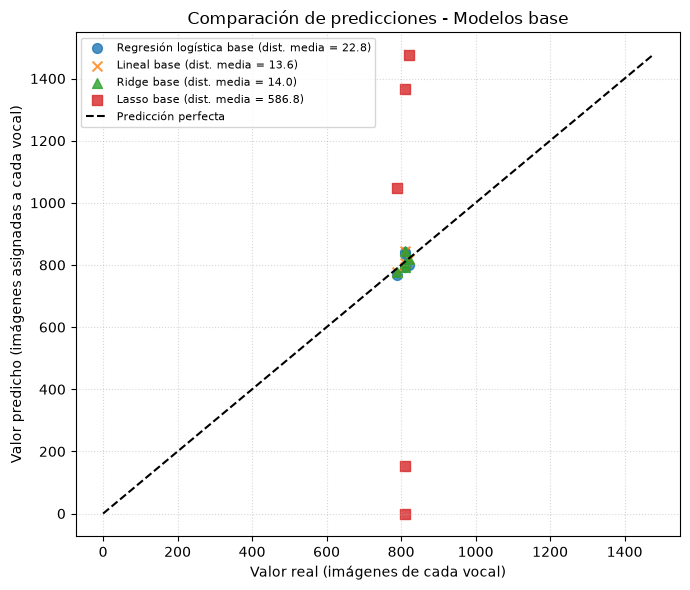

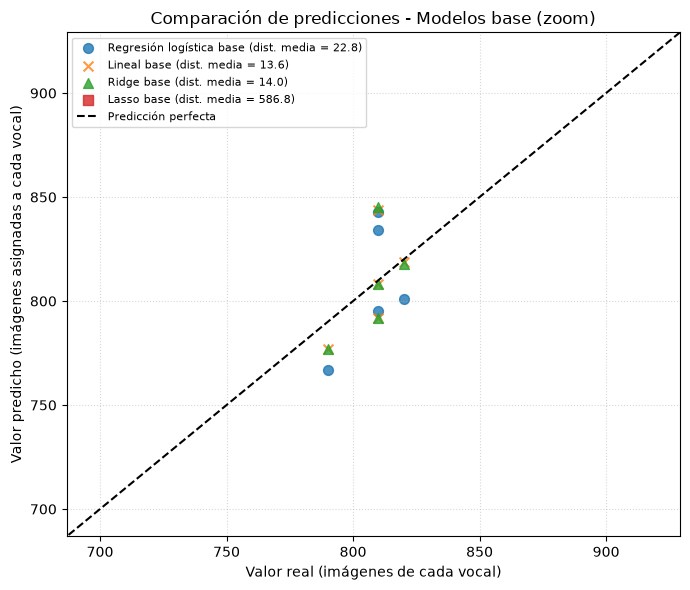

,Distancia media (imágenes por vocal),Distancia máxima (imágenes),Vocal más desviada,RMSE one-hot (por imagen)
Modelo,,,,
Regresión logística base,22.8,33.0,U,0.0991
Lineal base,13.6,34.0,U,0.2016
Ridge base,14.0,35.0,U,0.2015
Lasso base,586.8,810.0,U,0.3714


In [124]:
modelos_base = {
    "Regresión logística base": (modelo_base, "predict_proba"),
    "Lineal base": (lineal_base, "decision_function"),
    "Ridge base":  (ridge_base,  "decision_function"),
    "Lasso base":  (lasso_base,  "decision_function"),
}
tabla_dist_base = comparacion_diagonal(modelos_base, "Comparación de predicciones - Modelos base")
mostrar(tabla_dist_base)

### Modelos ajustados

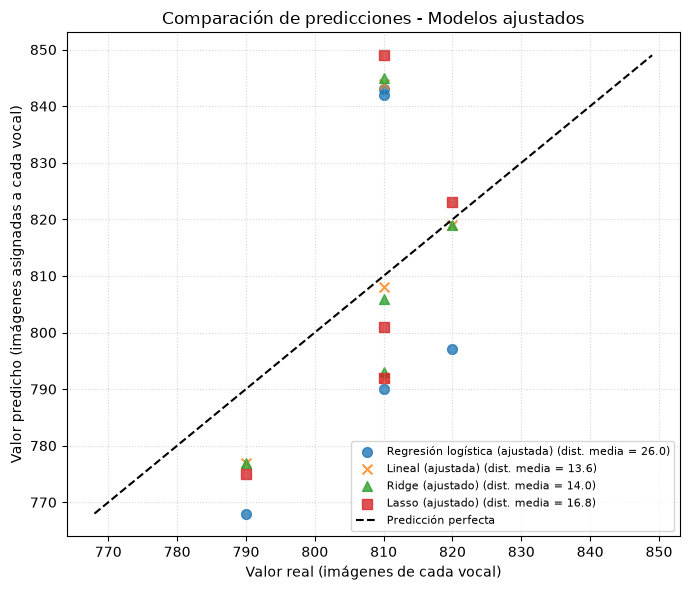

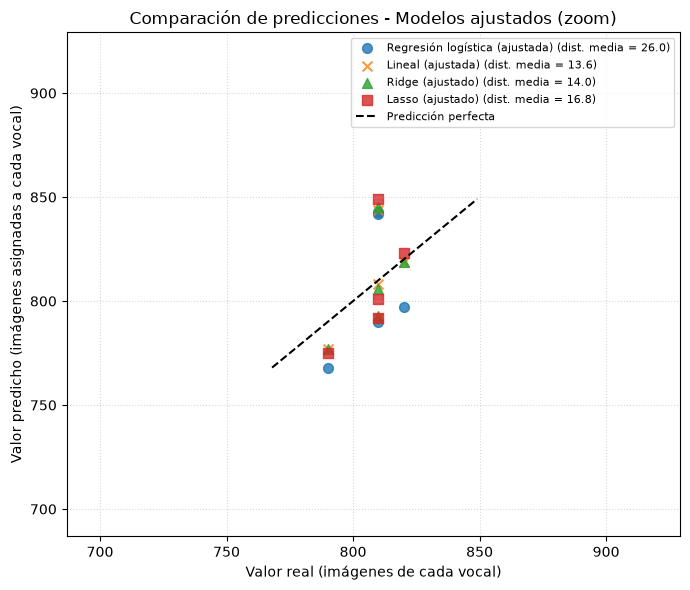

,Distancia media (imágenes por vocal),Distancia máxima (imágenes),Vocal más desviada,RMSE one-hot (por imagen)
Modelo,,,,
Regresión logística (ajustada),26.0,33.0,U,0.0959
Lineal (ajustada),13.6,34.0,U,0.2016
Ridge (ajustado),14.0,35.0,U,0.2012
Lasso (ajustado),16.8,39.0,U,0.1965


In [125]:
modelos_ajustados = {
    "Regresión logística (ajustada)": (gs_log.best_estimator_,    "predict_proba"),
    "Lineal (ajustada)":              (gs_lineal.best_estimator_, "decision_function"),
    "Ridge (ajustado)":               (gs_ridge.best_estimator_,  "decision_function"),
    "Lasso (ajustado)":               (gs_lasso.best_estimator_,  "decision_function"),
}
tabla_dist_aj = comparacion_diagonal(modelos_ajustados, "Comparación de predicciones - Modelos ajustados")
mostrar(tabla_dist_aj)

### Evaluación en prueba

,accuracy,precision,recall,especificidad,FPR,MSE,RMSE,MAE,log_loss
Lineal (ajustada),0.9369,0.9384,0.9365,0.9843,0.0157,0.0395,0.1986,0.1427,NaN
Ridge (ajustado),0.9369,0.9384,0.9365,0.9843,0.0157,0.0394,0.1986,0.1426,NaN
Lasso (ajustado),0.9320,0.9335,0.9315,0.9831,0.0169,0.0390,0.1974,0.1423,NaN
Regresión logística (ajustada),0.9544,0.9552,0.9541,0.9887,0.0113,NaN,NaN,NaN,0.0966


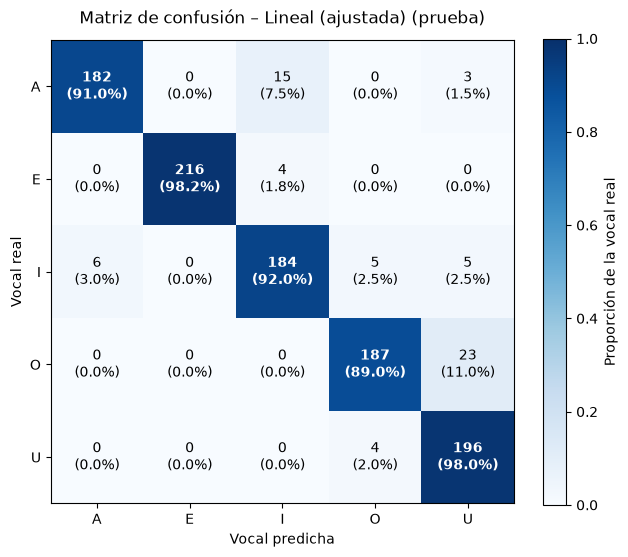

Lineal (ajustada): métricas por clase (prueba)


,precision,recall,f1-score,support,especificidad,FPR
A,0.9681,0.9100,0.9381,200.0,0.9928,0.0072
E,1.0000,0.9818,0.9908,220.0,1.0000,0.0000
I,0.9064,0.9200,0.9132,200.0,0.9771,0.0229
O,0.9541,0.8905,0.9212,210.0,0.9890,0.0110
U,0.8634,0.9800,0.9180,200.0,0.9627,0.0373


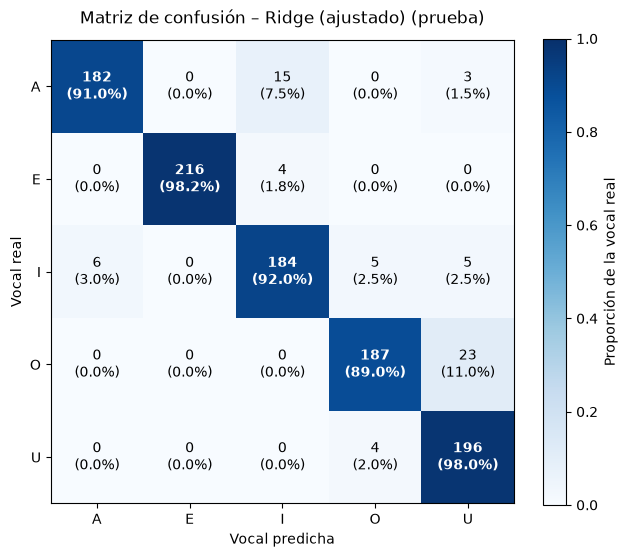

Ridge (ajustado): métricas por clase (prueba)


,precision,recall,f1-score,support,especificidad,FPR
A,0.9681,0.9100,0.9381,200.0,0.9928,0.0072
E,1.0000,0.9818,0.9908,220.0,1.0000,0.0000
I,0.9064,0.9200,0.9132,200.0,0.9771,0.0229
O,0.9541,0.8905,0.9212,210.0,0.9890,0.0110
U,0.8634,0.9800,0.9180,200.0,0.9627,0.0373


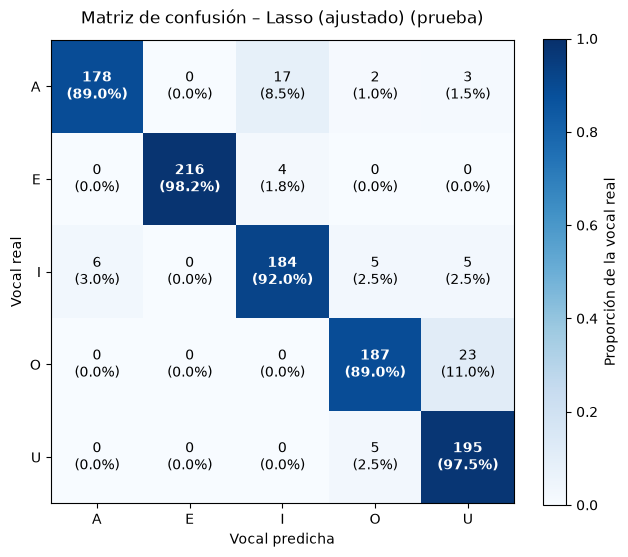

Lasso (ajustado): métricas por clase (prueba)


,precision,recall,f1-score,support,especificidad,FPR
A,0.9674,0.8900,0.9271,200.0,0.9928,0.0072
E,1.0000,0.9818,0.9908,220.0,1.0000,0.0000
I,0.8976,0.9200,0.9086,200.0,0.9747,0.0253
O,0.9397,0.8905,0.9144,210.0,0.9854,0.0146
U,0.8628,0.9750,0.9155,200.0,0.9627,0.0373


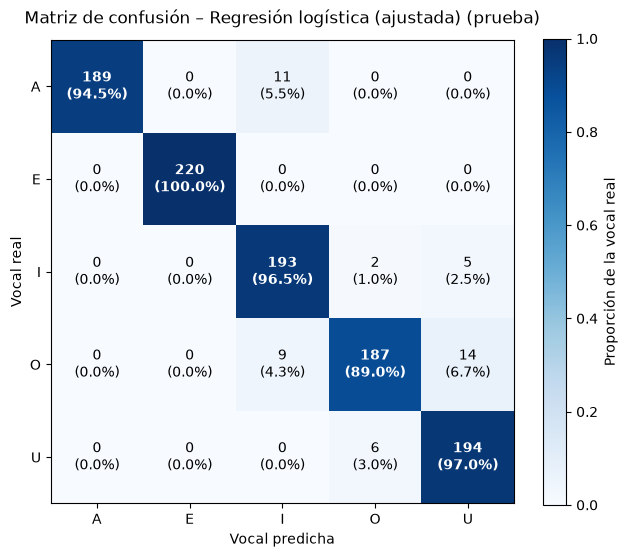

Regresión logística (ajustada): métricas por clase (prueba)


,precision,recall,f1-score,support,especificidad,FPR
A,1.0000,0.9450,0.9717,200.0,1.0000,0.0000
E,1.0000,1.0000,1.0000,220.0,1.0000,0.0000
I,0.9061,0.9650,0.9346,200.0,0.9759,0.0241
O,0.9590,0.8905,0.9235,210.0,0.9902,0.0098
U,0.9108,0.9700,0.9395,200.0,0.9771,0.0229


In [126]:
from sklearn.metrics import accuracy_score, log_loss

modelos_finales = {
    "Lineal (ajustada)":              gs_lineal.best_estimator_,
    "Ridge (ajustado)":               gs_ridge.best_estimator_,
    "Lasso (ajustado)":               gs_lasso.best_estimator_,
    "Regresión logística (ajustada)": gs_log.best_estimator_,
}

def evaluar_en_prueba(est, X_te, y_te):
    yp = est.predict(X_te)
    esp = especificidad_macro(y_te, yp)
    fila = {"accuracy":      accuracy_score(y_te, yp),
            "precision":     precision_score(y_te, yp, average="macro", zero_division=0),
            "recall":        recall_score(y_te, yp, average="macro", zero_division=0),
            "especificidad": esp, "FPR": 1 - esp}
    if hasattr(est, "predict_proba"):
        fila["log_loss"] = log_loss(y_te, est.predict_proba(X_te), labels=est.classes_)
    else:
        Y, P = _onehot(y_te), est.decision_function(X_te)
        fila["MSE"]  = mean_squared_error(Y, P)
        fila["RMSE"] = np.sqrt(fila["MSE"])
        fila["MAE"]  = mean_absolute_error(Y, P)
    return fila, yp

filas_prueba, pred_prueba = {}, {}
for nombre, est in modelos_finales.items():
    filas_prueba[nombre], pred_prueba[nombre] = evaluar_en_prueba(est, X_test_PCA, y_test)

res_prueba = pd.DataFrame(filas_prueba).T.round(4)
mostrar(res_prueba)

for nombre, yp in pred_prueba.items():
    rep, cm = metricas_por_clase(y_test, yp, CLASES)
    graficar_matriz_confusion(cm, CLASES, f"Matriz de confusión – {nombre} (prueba)")
    print(f"{nombre}: métricas por clase (prueba)")
    mostrar(rep.round(4))

In [129]:
import numpy as np
import pandas as pd
import os

METRICAS = ["accuracy", "precision", "recall", "especificidad", "FPR", "log_loss", "MSE", "RMSE", "MAE"]
BUSQUEDAS = {"Lineal (ajustada)": gs_lineal, "Ridge (ajustado)": gs_ridge,
             "Lasso (ajustado)": gs_lasso, "Regresión logística (ajustada)": gs_log}

filas_csv = []
for nombre, gs in BUSQUEDAS.items():
    val = resultados[nombre]["resumen"]
    fila = {"modelo": nombre,
            "hiperparametros": ", ".join(f"{k}={v}" for k, v in gs.best_params_.items())}
    for m in METRICAS:
        fila[f"{m}_val_media"] = val.loc[m, "validación (media)"] if m in val.index else np.nan
        fila[f"{m}_val_std"]   = val.loc[m, "validación (std)"]   if m in val.index else np.nan
        fila[f"{m}_prueba"]    = res_prueba.loc[nombre].get(m, np.nan)
    filas_csv.append(fila)

tabla_csv = pd.DataFrame(filas_csv).set_index("modelo").round(4)

# NUEVO: Mostrar la tabla en la consola/notebook antes de guardarla
print("--- CONTENIDO DE LA TABLA A GUARDAR ---")
display(tabla_csv) 



--- CONTENIDO DE LA TABLA A GUARDAR ---


,hiperparametros,accuracy_val_media,accuracy_val_std,accuracy_prueba,precision_val_media,precision_val_std,precision_prueba,recall_val_media,recall_val_std,recall_prueba,...,log_loss_prueba,MSE_val_media,MSE_val_std,MSE_prueba,RMSE_val_media,RMSE_val_std,RMSE_prueba,MAE_val_media,MAE_val_std,MAE_prueba
modelo,,,,,,,,,,,,,,,,,,,,,
Lineal (ajustada),"fit_intercept=True, positive=False",0.8646,0.0108,0.9369,0.8695,0.0086,0.9384,0.8650,0.0108,0.9365,...,NaN,0.1345,0.0184,0.0395,0.3660,0.0248,0.1986,0.2575,0.0125,0.1427
Ridge (ajustado),"alpha=5, fit_intercept=True",0.9475,0.0129,0.9369,0.9506,0.0111,0.9384,0.9483,0.0124,0.9365,...,NaN,0.0504,0.0088,0.0394,0.2238,0.0190,0.1986,0.1532,0.0069,0.1426
Lasso (ajustado),"alpha=0.001, fit_intercept=True",0.9565,0.0115,0.9320,0.9584,0.0104,0.9335,0.9569,0.0112,0.9315,...,NaN,0.0365,0.0037,0.0390,0.1907,0.0097,0.1974,0.1364,0.0063,0.1423
Regresión logística (ajustada),"C=0.05, solver=newton-cg",0.9742,0.0078,0.9544,0.9765,0.0067,0.9552,0.9746,0.0079,0.9541,...,0.0966,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
